# Etapa 10b · Poda e fine-tuning de recuperação do XLM-R: quanto dá para tirar, e de onde

| | |
|---|---|
| **Pergunta** | Quanto dá para tirar do XLM-R, de que parte, e quanto o reajuste recupera? |
| **Entrada** | `entregas/01_dados/` (os pedidos), `entregas/10a_encoder/` (o teto e os alunos com o XLM-R, a decisão e o sinal de treino de cada um), `entregas/07_poda/` (a curva da rede do zero, para pôr ao lado) e as execuções gravadas pelos comandos de `especialista/experimentos/etapa10b.py`. |
| **Entrega** | `entregas/10b_encoder_poda/`: a curva de qualidade por esparsidade, antes e depois do reajuste; o corte do vocabulário e das camadas; o que cada corte muda de verdade em parâmetros, bytes e milissegundos; os modelos que seguem para a quantização (Etapa 10c) e o `decisao.json` que diz onde estão. |
| **Pronto quando** | (1) cada variante tem 3 sementes, com o mesmo orçamento de reajuste; (2) a esparsidade pedida é a obtida; (3) nenhum rótulo humano entrou no reajuste dos alunos; (4) a escolha das linhas do vocabulário não usou `dev` nem o teste; (5) cada variante tem a medida antes e depois do reajuste, com comparação pareada contra o mesmo modelo sem poda e intervalo de 95%, no teste; (6) tamanho e latência foram medidos em arquivos gravados e modelos carregados, com a rede separada do tokenizador; (7) o que segue para a quantização saiu de `dev`, pela regra escrita antes; (8) os modelos entregues reproduzem as respostas do teste. |

**De onde esta etapa parte.** A Etapa 7 podou a rede do zero (4,9 milhões de parâmetros). Aqui o mesmo roteiro é aplicado ao XLM-R base da Etapa 10a, que é 57 vezes maior e tem uma forma muito diferente: 69% dos parâmetros estão numa tabela de subtokens feita para 100 idiomas, e o resto, num corpo de 12 camadas. **Podar** é tirar o que menos faz falta e treinar mais um pouco para o que ficou compensar; esse treino a mais é o **reajuste**. Tira-se de dois jeitos: **pesos soltos**, espalhados pelas matrizes, ou **peças inteiras** (linhas da tabela, camadas).

**Artigos de apoio**

- Treinar, podar pelos pesos de menor valor absoluto e treinar de novo: Han et al., *Learning both Weights and Connections for Efficient Neural Networks* ([arXiv 1506.02626](https://arxiv.org/abs/1506.02626)).
- Poda gradual, com a esparsidade subindo durante o treino: Zhu & Gupta, *To prune, or not to prune* ([arXiv 1710.01878](https://arxiv.org/abs/1710.01878)).
- Poda por magnitude no BERT, matriz por matriz (6 por camada): Gordon, Duh & Andrews, *Compressing BERT: Studying the Effects of Weight Pruning on Transfer Learning* ([arXiv 2002.08307](https://arxiv.org/abs/2002.08307)). De 30% a 40% dos pesos saem sem perda; daí para cima a qualidade cai.
- Magnitude contra outros critérios num encoder pré-treinado, com a mesma curva cúbica: Sanh, Wolf & Rush, *Movement Pruning: Adaptive Sparsity by Fine-Tuning* ([arXiv 2005.07683](https://arxiv.org/abs/2005.07683)). As tabelas de entrada ficam fora da poda e a esparsidade é contada no corpo.
- Tirar as camadas de cima de um encoder já treinado e ajustar: Sajjad, Dalvi, Durrani & Nakov, *On the Effect of Dropping Layers of Pre-trained Transformer Models* ([arXiv 2004.03844](https://arxiv.org/abs/2004.03844)).
- Cortar da tabela os subtokens que o corpus da tarefa não usa, e do tokenizador junto: Yang, Cui & Chen, *TextPruner: A Model Pruning Toolkit for Pre-Trained Language Models* ([arXiv 2203.15996](https://arxiv.org/abs/2203.15996)).
- Num modelo multilíngue, a maior parte dos parâmetros está na tabela, e ficar só com os idiomas que interessam encolhe o modelo: Abdaoui, Pradel & Sigel, *Load What You Need: Smaller Versions of Multilingual BERT* ([arXiv 2010.05609](https://arxiv.org/abs/2010.05609)).
- Máscara travada no reajuste, só com o sinal do professor: Zafrir et al., *Prune Once for All* ([arXiv 2111.05754](https://arxiv.org/abs/2111.05754)).
- Guardar só os pesos que ficaram, e a ordem podar e depois quantizar: Han et al., *Deep Compression* ([arXiv 1510.00149](https://arxiv.org/abs/1510.00149)).
- Como reportar poda (tamanho e velocidade, controle, sementes): Blalock et al., *What is the State of Neural Network Pruning?* ([arXiv 2003.03033](https://arxiv.org/abs/2003.03033)). Parâmetros, bytes e tempo não são a mesma medida: Dehghani et al., *The Efficiency Misnomer* ([arXiv 2110.12894](https://arxiv.org/abs/2110.12894)).
- O encoder e a cabeça conjunta: Conneau et al., XLM-R ([arXiv 1911.02116](https://arxiv.org/abs/1911.02116)); Chen et al., JointBERT ([arXiv 1902.10909](https://arxiv.org/abs/1902.10909)).

In [1]:
import json
import os
import shutil
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import qualidade, resultados
from especialista.avaliacao.previsao import ouro, salvar_previsoes
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.compressao import poda_encoder
from especialista.dados import massive
from especialista.experimentos import etapa10b
from especialista.modelos.encoder import SistemaEncoder

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PASTA = entrega("10b_encoder_poda")
SEMENTES, NIVEIS, VARIANTES, CURTAS = etapa10b.SEMENTES, etapa10b.ESPARSIDADES, etapa10b.VARIANTES, etapa10b.CURTAS
EPOCAS, RAMPA, CORTES = etapa10b.EPOCAS, etapa10b.EPOCAS_DE_RAMPA, etapa10b.PASSOS_ENTRE_CORTES
assert (EPOCAS, RAMPA, CORTES, etapa10b.EPOCAS_CURTAS) == (10, 5, 100, 4), "O texto deste notebook foi gerado com outro orçamento de reajuste: gere o notebook de novo."

MODELOS = etapa10b.modelos_a_podar()                                        # o aluno principal, o outro aluno, o teto
PRINCIPAL = etapa10b.modelo_principal()
COMPLETOS = [m for m in MODELOS if MODELOS[m]["grade"] == "completa"]       # os que têm a grade inteira
DEPENDENTES = [m for m in MODELOS if MODELOS[m]["grade"] != "completa"]     # o que só recebe o que segue do principal
ALUNOS = [m for m in MODELOS if m != "teto"]
CURTO = {m: MODELOS[m]["curto"] for m in MODELOS}
NOME = {**{v: d["nome"] for v, d in VARIANTES.items()}, **{v: d["nome"] for v, d in CURTAS.items()}}

DE_UMA_VEZ = {s: f"magnitude_{s}" for s in NIVEIS}
GRADUAL = {s: f"gradual_{s}" for s in NIVEIS}
PODADAS = [v for v in VARIANTES if VARIANTES[v]["familia"] != "controle"]
PECAS = [v for v in PODADAS if VARIANTES[v]["familia"] in etapa10b.PECAS_INTEIRAS]
SOLTAS = [v for v in PODADAS if VARIANTES[v]["familia"] in etapa10b.PESOS_SOLTOS]
COM_ANTES = [v for v in PODADAS if VARIANTES[v]["familia"] not in etapa10b.SEM_ANTES]
ORDEM = ["sem_poda", *DE_UMA_VEZ.values(), *GRADUAL.values(), *PECAS]      # a ordem das tabelas

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
gabarito = {"dev": ouro(dev), "test": ouro(teste)}
TRES = ("intent_acc", "slot_f1", "exact_match")   # as três métricas das leituras


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def mb(x):
    return f"{x / 1e6:,.1f}".replace(",", "#").replace(".", ",").replace("#", ".")


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def trio(linha, coluna_do_valor="valor"):
    """Valor e intervalo de uma linha de tabela, em pontos percentuais, para os gráficos."""
    return tuple(100 * linha[c] for c in (coluna_do_valor, "ic_min", "ic_max"))


def lista(itens, vazio="nenhum"):
    """"a", "a e b", "a, b e c"."""
    itens = [str(i) for i in itens]
    return vazio if not itens else itens[0] if len(itens) == 1 else ", ".join(itens[:-1]) + " e " + itens[-1]


def minusculo(texto):
    return texto[0].lower() + texto[1:]


curva = visual.curva_com_intervalo

## 1. Onde estão os pesos do XLM-R

Antes de cortar, a conta de onde os parâmetros estão. É ela que diz o que cada tipo de corte pode alcançar.

In [2]:
de_partida = json.loads((ENTREGAS / etapa10b.DECISAO_DO_ENCODER).read_text(encoding="utf-8"))["custo_de_partida"]
partes, total = de_partida["parametros_por_parte"], de_partida["parametros"]
PODAVEIS = 12 * (4 * 768 * 768 + 2 * 768 * 3072)      # as 72 matrizes do corpo (conferido num teste e na seção 4)
LINHAS, USADAS = de_partida["linhas_da_tabela_de_subtokens"], de_partida["linhas_da_tabela_usadas_no_treino"]
quem_alcanca = {
    "A. Tabela de subtokens": "o corte do vocabulário (linhas inteiras)",
    "A. Posições e normalização da entrada": "nada",
    "B. Corpo do Transformer": "a poda por magnitude (pesos soltos) e o corte de camadas",
    "C. Cabeça de intenção": "nada", "D. Cabeça de entidades": "nada",
}
display(pd.DataFrame([
    {"parte": parte, "parâmetros": n(quantos), "parte do modelo": f"{pts(quantos / total)}%", "o que esta etapa pode tirar daí": quem_alcanca[parte]}
    for parte, quantos in partes.items()
] + [{"parte": "Total", "parâmetros": n(total), "parte do modelo": "100,0%", "o que esta etapa pode tirar daí": ""}]).set_index("parte"))
display(Markdown(f"""
**Leitura.**

- **A poda por magnitude age em {n(PODAVEIS)} pesos**: as 6 matrizes de cada uma das 12 camadas. São {pts(PODAVEIS / partes['B. Corpo do Transformer'])}% do corpo, mas só {pts(PODAVEIS / total)}% do modelo. Mesmo com 90% desses pesos em zero, {pts(1 - 0.9 * PODAVEIS / total)}% dos parâmetros do modelo continuam diferentes de zero.
- **A tabela tem {n(LINHAS)} linhas e o treino em português usa {n(USADAS)}** ({pts(USADAS / LINHAS)}%). Cada linha tem 768 números. É aqui que está a maior parte do tamanho, e é o corte do vocabulário que chega nela.
- **Cada camada do corpo tem {n(partes['B. Corpo do Transformer'] / 12)} parâmetros** ({pts(partes['B. Corpo do Transformer'] / 12 / total)}% do modelo). Tirar camadas diminui pouco o arquivo, mas é o único corte que diminui a conta feita a cada consulta.
"""))

,parâmetros,parte do modelo,o que esta etapa pode tirar daí
parte,,,
A. Tabela de subtokens,192.001.536,"69,2%",o corte do vocabulário (linhas inteiras)
A. Posições e normalização da entrada,397.056,"0,1%",nada
B. Corpo do Transformer,85.054.464,"30,6%",a poda por magnitude (pesos soltos) e o corte de camadas
C. Cabeça de intenção,46.140,"0,0%",nada
D. Cabeça de entidades,85.359,"0,0%",nada
Total,277.584.555,"100,0%",



**Leitura.**

- **A poda por magnitude age em 84.934.656 pesos**: as 6 matrizes de cada uma das 12 camadas. São 99,9% do corpo, mas só 30,6% do modelo. Mesmo com 90% desses pesos em zero, 72,5% dos parâmetros do modelo continuam diferentes de zero.
- **A tabela tem 250.002 linhas e o treino em português usa 5.196** (2,1%). Cada linha tem 768 números. É aqui que está a maior parte do tamanho, e é o corte do vocabulário que chega nela.
- **Cada camada do corpo tem 7.087.872 parâmetros** (2,6% do modelo). Tirar camadas diminui pouco o arquivo, mas é o único corte que diminui a conta feita a cada consulta.


## 2. O que ficou decidido antes de medir

Tudo abaixo estava escrito em `experimentos/etapa10b.py` e em `compressao/poda_encoder.py` antes de a grade rodar.

**1. Quem é podado.** A grade completa roda no **aluno A** (o modelo final deste caminho) e no **teto** (a referência: a compressão sem o efeito do professor). O **aluno B2** recebe só as duas variantes que a regra apontar como principal e secundária para o aluno A, para que exista a cadeia do cenário B no comparativo. Ele não tem grade nem regra própria.

**2. Com que sinal é reajustado.** Com o sinal de quem treinou o modelo: o aluno, com os rótulos (ou os logits) do seu professor, e a época de parada escolhida no `dev` rotulado pelo mesmo professor; o teto, com os rótulos humanos. Nenhum rótulo humano entra no reajuste de um aluno. É o que Zafrir et al. fazem ao reajustar um modelo esparso.

**3. Pesos soltos, por magnitude.** Em cada uma das 72 matrizes do corpo, saem os pesos de menor valor absoluto, na mesma fração em todas (corte por matriz, como em Gordon et al. e na Etapa 7). Níveis: 30%, 50%, 70%, 90%. Duas formas: **de uma vez** (Han et al.), com medida antes e depois do reajuste, e **gradual** (Zhu & Gupta), com a esparsidade subindo pela curva cúbica nas 5 primeiras épocas do reajuste, um corte a cada 100 passos, e a máscara travada nas 5 últimas.

**4. A tabela de subtokens fica fora da poda por magnitude.** Sanh et al. também deixam as tabelas de entrada de fora e contam a esparsidade no corpo. Gordon et al. podam a tabela "do mesmo jeito": aqui isso é um **desvio declarado**. O motivo: 98% das linhas da tabela nunca são lidas em português; zerar pesos nelas daria esparsidade de graça, sem dizer nada sobre a rede. A tabela é tratada pelo corte do vocabulário.

**5. Peças inteiras (i): o corte do vocabulário.** Saem linhas inteiras da tabela, e o tokenizador é reduzido às que ficam (é o que fazem o TextPruner e Abdaoui et al.). É o análogo das "linhas da tabela de features" da Etapa 7. Duas formas de escolher as linhas que ficam, e **nenhuma olha o texto de `dev` nem do teste**:

- **treino**: os subtokens que aparecem no texto de treino pt-PT (os pedidos, sem rótulo). É a escolha do TextPruner para o XLM-R.
- **alfabeto**: os subtokens escritos só com letras latinas, dígitos e pontuação. Não usa corpus nenhum; é uma escolha deste projeto, na linha de Abdaoui et al.

Uma palavra que usava uma peça cortada é partida de novo pelo tokenizador, em peças menores que ficaram; o que não tem peça nenhuma vira `<unk>`. A fração dos subtokens de `dev` que cada forma corta é relatada na seção 7, como diagnóstico: não escolhe nada.

**6. Peças inteiras (ii): as camadas de cima.** O corpo fica com as 8 e 6 camadas de baixo, das 12. Sajjad et al. comparam seis formas de descartar camadas, tirar as de cima é a melhor, e eles testam tirar 2, 4 e 6 das 12. **(iii) Duas combinações**, definidas antes: o vocabulário do treino com cada um dos dois cortes de camadas.

**7. O reajuste.** 10 épocas em todas as execuções, com a receita de quem treinou o modelo (taxa 5e-5, lote 32, a mesma agenda da taxa) e a máscara travada. É o orçamento do ajuste fino da Etapa 10a inteiro, como nos artigos de poda de encoders pré-treinados: Sajjad et al. tiram as camadas e fazem o ajuste fino de sempre; Sanh et al. podam durante o ajuste fino inteiro. É também o critério da Etapa 7, que deu ao reajuste as épocas que o treino original leva para chegar ao melhor ponto (30 de 80); aqui o treino chega ao melhor ponto entre a 7ª e a 10ª época, de 10. Fica o melhor ponto em `dev`, e o ponto de partida concorre como "época 0": se o reajuste não melhora o modelo, o modelo sai como entrou. Um **controle** faz o mesmo reajuste sem tirar nada. **Este orçamento veio de um piloto no teto**, mostrado logo abaixo: o primeiro desenho dava 4 épocas ao reajuste.

**8. O controle do orçamento.** Duas variantes do aluno A (magnitude de 90% e 6 camadas) são reajustadas também com 4 épocas: 40% do treino, a proporção que o reajuste teve na Etapa 7. Serve só para medir, no aluno, quanto o orçamento pesa na recuperação. Não entra na regra.

**9. A regra do que segue para a quantização**, a mesma da Etapa 7. Em `dev`, com os rótulos humanos: **passa** a variante cujo exact match, depois do reajuste, não é distinguivelmente menor que o do modelo sem poda (intervalo de 95% da diferença pareada, média de 3 sementes). A **principal** é a que passa com o menor arquivo comum; se nenhuma peça inteira passa, é o modelo sem poda. A **secundária** é a de pesos soltos que passa com a maior esparsidade.

**10. As comparações**, fixadas antes: cada variante contra o modelo sem poda (pareada, no teste, nas três métricas); depois × antes do reajuste; gradual × de uma vez no mesmo nível; reajuste de 10 épocas × de 4; e, no texto, a curva do XLM-R ao lado da curva da rede do zero, para o aluno A.

**11. O custo de cada variante.** Parâmetros e diferentes de zero; tamanho em três formatos (arquivo comum, com zip, arquivo esparso), com a rede separada do tokenizador; latência p50 em CPU com 1 thread, do texto à resposta.

**12. Como ler os resultados.** Gordon et al. veem o BERT aguentar de 30% a 40% dos pesos a menos sem perda, e cair daí para cima. Sanh et al. medem, com magnitude e 10% dos pesos do corpo, 77,8% no MNLI contra 84,5% do modelo inteiro. Sajjad et al. medem menos de 1 ponto de queda média no GLUE ao tirar 6 das 12 camadas do RoBERTa, e 2,9 pontos no BERT. O TextPruner corta o XLM-R de 1.060 MB para 406 MB só no vocabulário, sem perda no XNLI em inglês. A expectativa, então: os pesos soltos devem custar mais aqui do que na rede do zero, que aguentou 90%; o vocabulário deve sair quase de graça; as camadas ficam no meio.

**O que já tinha sido visto.** Um piloto com 6 execuções do teto (semente 0) rodou antes da grade, para medir o tempo e conferir a esparsidade. Ele mudou uma coisa no desenho: o orçamento do reajuste. As outras regras não mudaram depois dele, e as medidas dos alunos não tinham sido vistas. O que o piloto mostrou está gravado em `piloto.json`, ao lado das execuções:

In [3]:
piloto = json.loads((etapa10b.pasta_da_etapa() / "piloto.json").read_text(encoding="utf-8"))
do_piloto = lambda variante, epocas: next(e for e in piloto["execucoes"] if e["variante"] == variante and e["epocas"] == epocas)
display(pd.DataFrame([
    {
        "variante (teto, semente 0)": NOME[e["variante"]], "épocas de reajuste": e["epocas"],
        "exact match em dev antes do reajuste": pts(e["dev_antes"]["exact_match"]) if e.get("dev_antes") else "—",
        "exact match em dev depois": pts(e["dev"]["exact_match"]), "época escolhida": e["melhor_epoca"],
        "acurácia de intenção em dev, época por época": " ".join(pts(h["dev_intent_acc"], 0) for h in e["historico"]),
    }
    for e in piloto["execucoes"]
]).set_index("variante (teto, semente 0)"))
curto_do_piloto, longo_do_piloto = do_piloto("camadas_6", etapa10b.EPOCAS_CURTAS), do_piloto("camadas_6", EPOCAS)
decola = next(h["epoca"] for h in longo_do_piloto["historico"] if h["dev_intent_acc"] > 0.5)
display(Markdown(f"""
**Leitura do piloto (teto, semente 0, `dev`).**

- **Sem as 6 camadas de cima, {etapa10b.EPOCAS_CURTAS} épocas não bastam:** o exact match fica em {pts(curto_do_piloto["dev"]["exact_match"])}%. As entidades voltam (F1 de {pts(curto_do_piloto["historico"][-1]["dev_slot_f1"])}%), mas a intenção não: {pts(curto_do_piloto["historico"][-1]["dev_intent_acc"])}% de acurácia. A cabeça de intenção lê o primeiro token, e na 6ª camada ele ainda não resume o pedido; a rede precisa reaprender isso.
- **Com {EPOCAS} épocas, a mesma rede chega a {pts(longo_do_piloto["dev"]["exact_match"])}%** de exact match. A intenção só passa de 50% na {decola}ª época: num reajuste de {etapa10b.EPOCAS_CURTAS} épocas a taxa de aprendizado já está quase em zero nesse ponto.
- **Por isso o orçamento passou de {etapa10b.EPOCAS_CURTAS} para {EPOCAS} épocas, para todas as variantes.** Com o orçamento curto, o resultado das camadas seria decidido pelo orçamento, não pelo corte. O controle da seção 7 mede a mesma coisa no aluno A, com 3 sementes.
"""))

,épocas de reajuste,exact match em dev antes do reajuste,exact match em dev depois,época escolhida,"acurácia de intenção em dev, época por época"
"variante (teto, semente 0)",,,,,
6 das 12 camadas,4,"0,0","4,5",4,2 6 6 6 8
"Magnitude, 90% gradual",4,—,"26,4",4,46 40 54 56
"Magnitude, 50% de uma vez",4,"5,3","66,3",4,9 85 86 87 86
Vocabulário do treino,4,"66,7","66,7",0,87 86 85 87 87
Vocabulário do treino e 6 das 12 camadas,4,"0,0","4,4",4,2 6 6 6 8
6 das 12 camadas,10,—,"63,8",10,2 6 6 43 77 81 84 85 85 85 85



**Leitura do piloto (teto, semente 0, `dev`).**

- **Sem as 6 camadas de cima, 4 épocas não bastam:** o exact match fica em 4,5%. As entidades voltam (F1 de 75,0%), mas a intenção não: 7,9% de acurácia. A cabeça de intenção lê o primeiro token, e na 6ª camada ele ainda não resume o pedido; a rede precisa reaprender isso.
- **Com 10 épocas, a mesma rede chega a 63,8%** de exact match. A intenção só passa de 50% na 4ª época: num reajuste de 4 épocas a taxa de aprendizado já está quase em zero nesse ponto.
- **Por isso o orçamento passou de 4 para 10 épocas, para todas as variantes.** Com o orçamento curto, o resultado das camadas seria decidido pelo orçamento, não pelo corte. O controle da seção 7 mede a mesma coisa no aluno A, com 3 sementes.


## 3. As execuções

As execuções rodam fora do notebook (`uv run python -m especialista.experimentos.etapa10b onda`) e ficam gravadas em `data/execucoes/10b_encoder_poda/`. Aqui elas só são lidas.

In [4]:
faltam = etapa10b.faltam()
assert not faltam, ("Faltam execuções. Para listar: uv run python -m especialista.experimentos.etapa10b --faltam. Faltam: "
                    + ", ".join(f"{m} {v} {s}" for m, v, s in faltam[:12]) + (" ..." if len(faltam) > 12 else ""))
VARIANTES_DE = {m: etapa10b.variantes_do_modelo(m) for m in MODELOS}
exe = {m: {v: [etapa10b.carregar(m, v, s) for s in SEMENTES] for v in VARIANTES_DE[m]} for m in MODELOS}
exe[PRINCIPAL].update({v: [etapa10b.carregar(PRINCIPAL, v, s) for s in SEMENTES] for v in CURTAS})
# O modelo sem poda: as respostas que a Etapa 10a entregou
sem_poda = {m: {p: etapa10b.previsoes_sem_poda(m, p) for p in ("dev", "test")} for m in MODELOS}


def grupo(m, v, particao, momento="depois"):
    """As respostas das 3 sementes de uma variante, antes ou depois do reajuste."""
    return [e["previsoes"][particao if momento == "depois" else f"{particao}_antes"] for e in exe[m][v]]


todas = [(m, v, e) for m in MODELOS for v in exe[m] for e in exe[m][v]]
da_grade = [(m, v, e) for m, v, e in todas if v in VARIANTES]

# 1. Os modelos de partida são os que a Etapa 10a entregou: o "antes" do controle bate com as respostas gravadas lá
iguais_as_entregues = min(
    np.mean([a == b for a, b in zip(daqui, de_la)])
    for m in COMPLETOS for p in ("dev", "test") for daqui, de_la in zip(grupo(m, "sem_poda", p, "antes"), sem_poda[m][p])
)
# 2. O orçamento: toda execução tem as épocas declaradas e a receita de quem treinou o modelo
epocas_de = lambda v: etapa10b.definicao(v)["epocas"]
orcamento_confere = all(e["meta"]["receita"] == etapa10b.receita_do_reajuste(m, epocas_de(v)).como_dict()
                        and e["historico"]["epoca"].max() == epocas_de(v) for m, v, e in todas)
com_partida = [(m, v, e) for m, v, e in da_grade if VARIANTES[v]["familia"] not in etapa10b.SEM_ANTES]
ficou_na_partida = [(m, v, e) for m, v, e in com_partida if e["meta"]["melhor_epoca"] == 0]
# 3. A esparsidade pedida é a obtida, peso por peso
zeros_de = lambda e: e["meta"]["contagem"]["podaveis"] - e["meta"]["contagem"]["nao_nulos_podaveis"]
pesos_por_matriz = [768 * 768] * 48 + [768 * 3072] * 24
zeros_pedidos = lambda v: sum(round(VARIANTES[v]["nivel"] / 100 * pesos) for pesos in pesos_por_matriz)
soltas = [(m, v, e) for m, v, e in da_grade if v in SOLTAS]
sobra_de_zeros = max(zeros_de(e) - zeros_pedidos(v) for m, v, e in soltas)
falta_de_zeros = min(zeros_de(e) - zeros_pedidos(v) for m, v, e in soltas)
esparsidade_confere = 0 <= falta_de_zeros and sobra_de_zeros <= 100 and all(e["meta"]["contagem_de_partida"]["podaveis"] == PODAVEIS for m, v, e in todas)
sem_zeros_onde_nao_se_pediu = max(e["meta"]["contagem"]["esparsidade"] for m, v, e in da_grade if v not in SOLTAS)
# 4. A poda gradual seguiu a curva e só escolheu época depois da rampa
passos = int(exe[PRINCIPAL]["sem_poda"][0]["historico"]["passos"].max())
fim_da_rampa = RAMPA * passos // CORTES * CORTES
planejada = lambda s: np.array([poda_encoder.esparsidade_cubica(min(epoca * passos // CORTES * CORTES, fim_da_rampa), fim_da_rampa, s / 100)
                                for epoca in range(1, EPOCAS + 1)])
desvio_da_curva = max(np.abs(e["historico"]["esparsidade"].to_numpy() - planejada(s)).max() for s in NIVEIS for e in exe[PRINCIPAL][GRADUAL[s]])
gradual_confere = desvio_da_curva < 0.005 and all(e["meta"]["melhor_epoca"] >= RAMPA for m in COMPLETOS for s in NIVEIS for e in exe[m][GRADUAL[s]])
# 5. Nenhum rótulo humano no reajuste dos alunos: o sinal anotado em cada execução é o do professor
sem_humano = all(e["meta"]["origem"]["treino"].startswith("rótulos do professor") and e["meta"]["origem"]["dev"].startswith("rótulos do professor")
                 for m, v, e in todas if m in ALUNOS)
do_teto_e_humano = all(e["meta"]["origem"]["treino"].startswith("rótulos humanos") for m, v, e in todas if m == "teto")
# 6. O corte do vocabulário: as linhas que ficam não dependem de dev nem do teste (a forma "treino" cobre o treino inteiro, por construção)
cortes = [(m, v, e) for m, v, e in todas if e["meta"]["vocabulario"]]
treino_coberto = all(e["meta"]["vocabulario"]["cobertura"]["treino"]["subtokens_cortados"] == 0 for m, v, e in cortes if e["meta"]["vocabulario"]["forma"] == "treino")
mesmas_linhas = {forma: {e["meta"]["vocabulario"]["linhas"] for m, v, e in cortes if e["meta"]["vocabulario"]["forma"] == forma} for forma in etapa10b.FORMAS}

horas = sum(e["meta"]["segundos"] for m, v, e in todas) / 3600
onde_rodou = sorted({e["meta"]["respostas_em"] for m, v, e in todas})

epocas_escolhidas = lambda m, v: ", ".join(str(e["meta"]["melhor_epoca"]) for e in exe[m][v])
no_dev = lambda m, v, quando: np.mean([e["meta"][quando]["exact_match"] for e in exe[m][v]])
print(f"{MODELOS[PRINCIPAL]['nome']}: cada variante no dev que escolhe a época de parada (média de 3 sementes)")
pd.DataFrame([
    {
        "variante": NOME[v],
        "época escolhida (sementes 0, 1 e 2)": epocas_escolhidas(PRINCIPAL, v),
        "exact match antes do reajuste": pts(no_dev(PRINCIPAL, v, "dev_antes")) if exe[PRINCIPAL][v][0]["meta"]["dev_antes"] else "—",
        "exact match depois": pts(no_dev(PRINCIPAL, v, "dev")),
        "minutos por execução": num(np.mean([e["meta"]["segundos"] for e in exe[PRINCIPAL][v]]) / 60, 1),
    }
    for v in [*ORDEM, *CURTAS]
]).set_index("variante")

Aluno A (rótulos do Claude Haiku 5.5): cada variante no dev que escolhe a época de parada (média de 3 sementes)


,"época escolhida (sementes 0, 1 e 2)",exact match antes do reajuste,exact match depois,minutos por execução
variante,,,,
"Sem poda, com o mesmo reajuste (controle)","10, 0, 10","64,8","65,2","2,0"
"Magnitude, 30% de uma vez","6, 6, 8","59,2","65,1","2,1"
"Magnitude, 50% de uma vez","6, 7, 10","2,6","64,6","2,1"
"Magnitude, 70% de uma vez","10, 10, 10","1,0","60,0","2,1"
"Magnitude, 90% de uma vez","9, 10, 10","0,0","39,7","2,1"
"Magnitude, 30% gradual","10, 7, 9",—,"65,2","2,1"
"Magnitude, 50% gradual","6, 6, 10",—,"64,4","2,0"
"Magnitude, 70% gradual","10, 9, 10",—,"62,6","2,0"
"Magnitude, 90% gradual","10, 9, 8",—,"45,0","2,0"


In [5]:
display(Markdown(f"""
**Leitura.**

- **São {len(todas)} execuções**: {len(COMPLETOS)} modelos com a grade de {len(VARIANTES)} variantes × {len(SEMENTES)} sementes, {lista([f"{len(VARIANTES_DE[m])} variantes do {minusculo(CURTO[m])}" for m in DEPENDENTES])} e {len(CURTAS)} variantes do controle do orçamento. Somam {num(horas, 1)} horas de processamento, em {lista(onde_rodou)}.
- **Modelos de partida:** as respostas dos modelos sem poda, refeitas aqui antes do reajuste do controle, são iguais às que a Etapa 10a entregou em pelo menos {pts(iguais_as_entregues, 2)}% dos pedidos de cada conjunto.
- **Orçamento igual para todas:** {"confere" if orcamento_confere else "NÃO confere"} ({EPOCAS} épocas na grade, {etapa10b.EPOCAS_CURTAS} no controle do orçamento, com a receita de quem treinou o modelo).
- **Quando o reajuste não ajuda, ele não fica.** Em {len(ficou_na_partida)} das {len(com_partida)} execuções em que o ponto de partida concorre, o melhor ponto em `dev` foi o próprio ponto de partida (época 0).
- **Esparsidade pedida e obtida:** {"confere" if esparsidade_confere else "NÃO confere"}. Nas {len(soltas)} execuções de pesos soltos, o número de zeros nas matrizes podáveis é o pedido (faltam no máximo {max(0, -falta_de_zeros)} e sobram no máximo {sobra_de_zeros} pesos, em {n(PODAVEIS)}). Nas demais, a maior fração de zeros é {pts(sem_zeros_onde_nao_se_pediu, 3)}%.
- **Poda gradual:** {"confere" if gradual_confere else "NÃO confere"}. A esparsidade medida ao fim de cada época segue a curva cúbica (maior desvio: {pts(desvio_da_curva, 2)} ponto), e toda época escolhida é do fim da rampa para a frente (a partir da {RAMPA}ª).
- **Sem rótulo humano no reajuste dos alunos:** {"confere" if sem_humano and do_teto_e_humano else "NÃO confere"}.
- **O corte do vocabulário não olhou `dev` nem o teste:** a forma "treino" fica com {lista(n(x) for x in sorted(mesmas_linhas["treino"]))} linhas e cobre o treino inteiro ({"confere" if treino_coberto else "NÃO confere"}); a forma "alfabeto" fica com {lista(n(x) for x in sorted(mesmas_linhas["alfabeto"]))}, escolhidas só pela grafia.
"""))


**Leitura.**

- **São 102 execuções**: 2 modelos com a grade de 15 variantes × 3 sementes, 2 variantes do aluno B2 e 2 variantes do controle do orçamento. Somam 3,1 horas de processamento, em NVIDIA GeForce RTX 3080.
- **Modelos de partida:** as respostas dos modelos sem poda, refeitas aqui antes do reajuste do controle, são iguais às que a Etapa 10a entregou em pelo menos 100,00% dos pedidos de cada conjunto.
- **Orçamento igual para todas:** confere (10 épocas na grade, 4 no controle do orçamento, com a receita de quem treinou o modelo).
- **Quando o reajuste não ajuda, ele não fica.** Em 12 das 69 execuções em que o ponto de partida concorre, o melhor ponto em `dev` foi o próprio ponto de partida (época 0).
- **Esparsidade pedida e obtida:** confere. Nas 51 execuções de pesos soltos, o número de zeros nas matrizes podáveis é o pedido (faltam no máximo 0 e sobram no máximo 0 pesos, em 84.934.656). Nas demais, a maior fração de zeros é 0,000%.
- **Poda gradual:** confere. A esparsidade medida ao fim de cada época segue a curva cúbica (maior desvio: 0,00 ponto), e toda época escolhida é do fim da rampa para a frente (a partir da 5ª).
- **Sem rótulo humano no reajuste dos alunos:** confere.
- **O corte do vocabulário não olhou `dev` nem o teste:** a forma "treino" fica com 5.196 linhas e cobre o treino inteiro (confere); a forma "alfabeto" fica com 113.246, escolhidas só pela grafia.


## 4. Pesos soltos: antes e depois do reajuste

A poda por magnitude feita de uma vez, nos quatro níveis, no teste. Cada nível tem duas medidas: o modelo logo depois do corte (**antes** do reajuste) e o mesmo modelo reajustado com a máscara travada (**depois**). A referência é o modelo sem poda. O ponto de 0% da série "depois" é o controle: o mesmo reajuste, sem tirar nada.

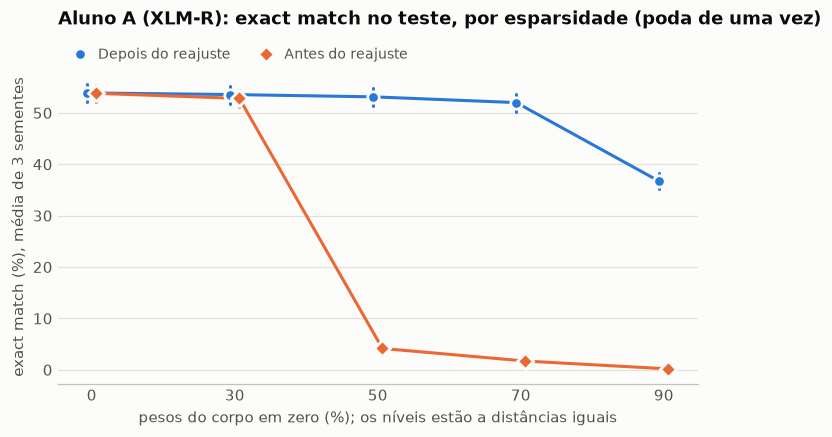

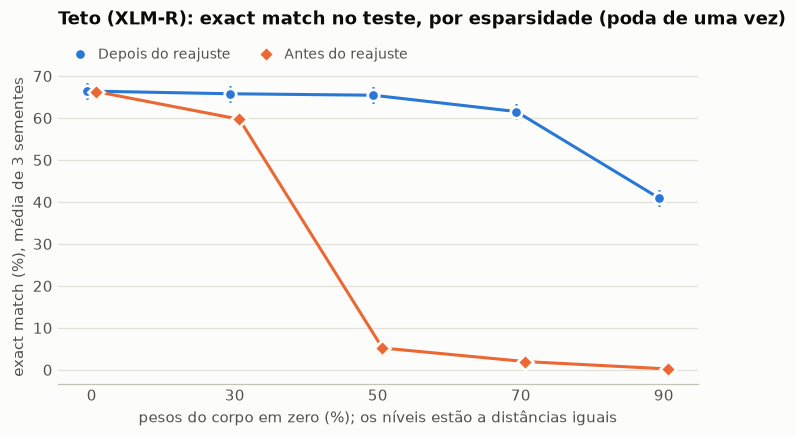

Aluno A (rótulos do Claude Haiku 5.5): exact match no teste, em % (intervalo de 95%); diferenças em pontos percentuais


,antes do reajuste,depois do reajuste,antes − sem poda,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem poda,"53,8 (52,1 a 55,4)",—,—,—,—
"Sem poda, com o mesmo reajuste (controle)",—,"53,9 (52,1 a 55,5)",—,"+0,1 (−0,4 a +0,5)",—
"Magnitude, 30% de uma vez","52,8 (51,2 a 54,4)","53,6 (51,8 a 55,2)","−1,0 (−2,0 a +0,0)","−0,2 (−0,8 a +0,3)","+0,8 (−0,3 a +1,7)"
"Magnitude, 50% de uma vez","4,2 (3,6 a 4,7)","53,1 (51,4 a 54,8)","−49,7 (−51,4 a −47,8)","−0,7 (−1,3 a −0,1)","+49,0 (+47,1 a +50,7)"
"Magnitude, 70% de uma vez","1,7 (1,4 a 2,0)","52,0 (50,3 a 53,7)","−52,1 (−53,8 a −50,3)","−1,8 (−2,8 a −0,9)","+50,3 (+48,5 a +52,0)"
"Magnitude, 90% de uma vez","0,2 (0,1 a 0,3)","36,7 (35,1 a 38,2)","−53,6 (−55,3 a −51,9)","−17,1 (−18,7 a −15,5)","+36,5 (+34,9 a +38,1)"


Aluno A (rótulos do Claude Haiku 5.5): as três métricas no teste, depois do reajuste, contra o modelo sem poda (pontos percentuais, intervalo de 95%)


,Acurácia de intenção,F1 de entidades,Exact match
0% (controle),"+0,2 (−0,2 a +0,5)","−0,1 (−0,5 a +0,3)","+0,1 (−0,4 a +0,5)"
30%,"−0,0 (−0,5 a +0,4)","−0,4 (−1,0 a +0,1)","−0,2 (−0,8 a +0,3)"
50%,"−0,1 (−0,6 a +0,4)","−0,5 (−1,0 a +0,0)","−0,7 (−1,3 a −0,1)"
70%,"−1,3 (−2,0 a −0,6)","−2,4 (−3,2 a −1,5)","−1,8 (−2,8 a −0,9)"
90%,"−10,9 (−12,2 a −9,6)","−17,1 (−18,7 a −15,5)","−17,1 (−18,7 a −15,5)"



Teto (rótulos humanos): exact match no teste


,antes do reajuste,depois do reajuste,antes − sem poda,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem poda,"66,3 (64,7 a 67,9)",—,—,—,—
"Sem poda, com o mesmo reajuste (controle)",—,"66,4 (64,9 a 68,0)",—,"+0,1 (−0,2 a +0,5)",—
"Magnitude, 30% de uma vez","59,7 (58,1 a 61,3)","65,8 (64,2 a 67,3)","−6,6 (−7,7 a −5,4)","−0,5 (−1,1 a +0,1)","+6,1 (+4,9 a +7,2)"
"Magnitude, 50% de uma vez","5,2 (4,5 a 5,9)","65,4 (63,9 a 67,0)","−61,1 (−62,9 a −59,4)","−0,9 (−1,5 a −0,2)","+60,2 (+58,5 a +61,9)"
"Magnitude, 70% de uma vez","2,0 (1,7 a 2,3)","61,5 (59,9 a 63,2)","−64,3 (−65,9 a −62,7)","−4,7 (−5,7 a −3,8)","+59,6 (+58,0 a +61,3)"
"Magnitude, 90% de uma vez","0,2 (0,1 a 0,3)","40,9 (39,3 a 42,5)","−66,1 (−67,7 a −64,5)","−25,4 (−26,9 a −23,8)","+40,7 (+39,1 a +42,3)"


In [6]:
_medidas, _contra, _recupera = {}, {}, {}


def medida(m, v, momento="depois", p="test"):
    """Valor e intervalo de 95% de cada métrica, média de 3 sementes. `v=None` é o modelo sem poda."""
    chave = (m, v, momento, p)
    if chave not in _medidas:
        _medidas[chave] = qualidade.intervalo_do_grupo(gabarito[p], sem_poda[m][p] if v is None else grupo(m, v, p, momento))
    return _medidas[chave]


def contra(m, v, momento="depois", p="test"):
    """Comparação pareada: a variante menos o mesmo modelo sem poda."""
    chave = (m, v, momento, p)
    if chave not in _contra:
        _contra[chave] = qualidade.comparar_grupos(gabarito[p], sem_poda[m][p], grupo(m, v, p, momento))
    return _contra[chave]


def recupera(m, v, p="test"):
    """Comparação pareada: depois do reajuste menos antes."""
    chave = (m, v, p)
    if chave not in _recupera:
        _recupera[chave] = qualidade.comparar_grupos(gabarito[p], grupo(m, v, p, "antes"), grupo(m, v, p, "depois"))
    return _recupera[chave]


def tem_antes(v):
    return etapa10b.definicao(v).get("familia_de_base", etapa10b.definicao(v)["familia"]) not in etapa10b.SEM_ANTES


def quadro(m, variantes, metrica="exact_match", p="test"):
    """Uma linha por variante: antes, depois, cada um contra o modelo sem poda, e o que o reajuste recupera."""
    linhas = {"Sem poda": {"antes do reajuste": valor_com_intervalo(medida(m, None, p=p).loc[metrica]), "depois do reajuste": "—",
                           "antes − sem poda": "—", "depois − sem poda": "—", "o que o reajuste recupera (depois − antes)": "—"}}
    for v in variantes:
        antes = tem_antes(v) and v != "sem_poda"
        linhas[NOME[v]] = {
            "antes do reajuste": valor_com_intervalo(medida(m, v, "antes", p).loc[metrica]) if antes else "—",
            "depois do reajuste": valor_com_intervalo(medida(m, v, "depois", p).loc[metrica]),
            "antes − sem poda": com_intervalo(contra(m, v, "antes", p).loc[metrica]) if antes else "—",
            "depois − sem poda": com_intervalo(contra(m, v, "depois", p).loc[metrica]),
            "o que o reajuste recupera (depois − antes)": com_intervalo(recupera(m, v, p).loc[metrica]) if antes else "—",
        }
    return pd.DataFrame(linhas).T


def pontos_da_curva(m, por_nivel, momento, metrica="exact_match", p="test"):
    """Os pontos de uma série da curva: 0% é o modelo sem poda (antes) ou o controle (depois)."""
    zero = medida(m, None, p=p) if momento == "antes" else medida(m, "sem_poda", "depois", p)
    return {0: trio(zero.loc[metrica]), **{s: trio(medida(m, v, momento, p).loc[metrica]) for s, v in por_nivel.items()}}


for m in COMPLETOS:
    fig, ax = curva(
        {"Depois do reajuste": pontos_da_curva(m, DE_UMA_VEZ, "depois"), "Antes do reajuste": pontos_da_curva(m, DE_UMA_VEZ, "antes")},
        f"{CURTO[m]} (XLM-R): exact match no teste, por esparsidade (poda de uma vez)", "pesos do corpo em zero (%); os níveis estão a distâncias iguais",
        "exact match (%), média de 3 sementes", niveis=True,
    )
    visual.salvar(fig, PASTA, f"curva_{m}")
    plt.show()

print(f"{MODELOS[PRINCIPAL]['nome']}: exact match no teste, em % (intervalo de 95%); diferenças em pontos percentuais")
display(quadro(PRINCIPAL, ["sem_poda", *DE_UMA_VEZ.values()]))
print(f"{MODELOS[PRINCIPAL]['nome']}: as três métricas no teste, depois do reajuste, contra o modelo sem poda (pontos percentuais, intervalo de 95%)")
display(pd.DataFrame({
    ("0% (controle)" if v == "sem_poda" else f"{VARIANTES[v]['nivel']}%"): {qualidade.NOMES[metrica]: com_intervalo(contra(PRINCIPAL, v).loc[metrica]) for metrica in TRES}
    for v in ["sem_poda", *DE_UMA_VEZ.values()]
}).T)
for m in COMPLETOS:
    if m != PRINCIPAL:
        print(f"\n{MODELOS[m]['nome']}: exact match no teste")
        display(quadro(m, ["sem_poda", *DE_UMA_VEZ.values()]))

In [7]:
def niveis_onde(m, por_nivel, momento, condicao, p="test"):
    return [f"{s}%" for s, v in por_nivel.items() if condicao(contra(m, v, momento, p).loc["exact_match"])]


def leitura_dos_pesos_soltos(m):
    cai_antes = niveis_onde(m, DE_UMA_VEZ, "antes", lambda l: l["ic_max"] < 0)
    cai_depois = niveis_onde(m, DE_UMA_VEZ, "depois", lambda l: l["ic_max"] < 0)
    recuperou = [f"{s}%" for s, v in DE_UMA_VEZ.items() if recupera(m, v).loc["exact_match", "ic_min"] > 0]
    ultimo = DE_UMA_VEZ[max(NIVEIS)]
    return (
        f"sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em {lista(cai_antes, 'nenhum nível')}; "
        f"com reajuste, em {lista(cai_depois, 'nenhum nível')}. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em {lista(recuperou, 'nenhum nível')}. "
        f"Em {max(NIVEIS)}%: {com_intervalo(contra(m, ultimo, 'antes').loc['exact_match'])} antes e {com_intervalo(contra(m, ultimo, 'depois').loc['exact_match'])} depois"
    )


controle = contra(PRINCIPAL, "sem_poda")
display(Markdown(f"""
**Leitura (teste, exact match).**

- **{CURTO[PRINCIPAL]}:** {leitura_dos_pesos_soltos(PRINCIPAL)}.
- **O que o reajuste recupera**, nível a nível ({CURTO[PRINCIPAL]}): {"; ".join(f"{s}%: {com_intervalo(recupera(PRINCIPAL, v).loc['exact_match'])}" for s, v in DE_UMA_VEZ.items())}.
- **O controle.** O mesmo reajuste, sem tirar nada, deixa o {minusculo(CURTO[PRINCIPAL])} {posicao(controle.loc['exact_match'])} em relação a si mesmo ({com_intervalo(controle.loc['exact_match'])} em exact match; {com_intervalo(controle.loc['intent_acc'])} em intenção; {com_intervalo(controle.loc['slot_f1'])} em entidades).
""" + "".join(f"- **{CURTO[m]}:** {leitura_dos_pesos_soltos(m)}.\n" for m in COMPLETOS if m != PRINCIPAL)))


**Leitura (teste, exact match).**

- **Aluno A:** sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em 50%, 70% e 90%; com reajuste, em 50%, 70% e 90%. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em 50%, 70% e 90%. Em 90%: −53,6 (−55,3 a −51,9) antes e −17,1 (−18,7 a −15,5) depois.
- **O que o reajuste recupera**, nível a nível (Aluno A): 30%: +0,8 (−0,3 a +1,7); 50%: +49,0 (+47,1 a +50,7); 70%: +50,3 (+48,5 a +52,0); 90%: +36,5 (+34,9 a +38,1).
- **O controle.** O mesmo reajuste, sem tirar nada, deixa o aluno A sem diferença distinguível em relação a si mesmo (+0,1 (−0,4 a +0,5) em exact match; +0,2 (−0,2 a +0,5) em intenção; −0,1 (−0,5 a +0,3) em entidades).
- **Teto:** sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em 30%, 50%, 70% e 90%; com reajuste, em 50%, 70% e 90%. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em 30%, 50%, 70% e 90%. Em 90%: −66,1 (−67,7 a −64,5) antes e −25,4 (−26,9 a −23,8) depois.


## 5. De uma vez ou gradual?

No mesmo nível de esparsidade e com o mesmo orçamento de 10 épocas: cortar tudo no começo ou subir a esparsidade aos poucos nas 5 primeiras épocas?

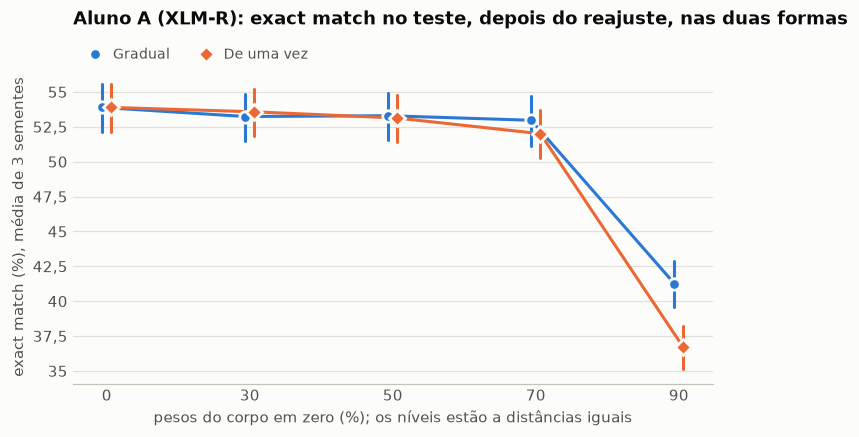

Aluno A (rótulos do Claude Haiku 5.5): exact match no teste


,"de uma vez, depois do reajuste",gradual,gradual − de uma vez,gradual − sem poda
30%,"53,6 (51,8 a 55,2)","53,2 (51,5 a 54,9)","−0,3 (−0,9 a +0,2)","−0,6 (−1,2 a +0,0)"
50%,"53,1 (51,4 a 54,8)","53,3 (51,5 a 54,9)","+0,2 (−0,3 a +0,7)","−0,5 (−1,2 a +0,1)"
70%,"52,0 (50,3 a 53,7)","53,0 (51,2 a 54,7)","+1,0 (+0,4 a +1,6)","−0,8 (−1,6 a −0,0)"
90%,"36,7 (35,1 a 38,2)","41,3 (39,6 a 42,9)","+4,6 (+3,6 a +5,5)","−12,5 (−13,9 a −11,1)"


Teto (rótulos humanos): exact match no teste


,"de uma vez, depois do reajuste",gradual,gradual − de uma vez,gradual − sem poda
30%,"65,8 (64,2 a 67,3)","65,3 (63,7 a 67,0)","−0,4 (−1,0 a +0,1)","−0,9 (−1,6 a −0,3)"
50%,"65,4 (63,9 a 67,0)","66,1 (64,5 a 67,7)","+0,7 (+0,1 a +1,2)","−0,2 (−0,8 a +0,4)"
70%,"61,5 (59,9 a 63,2)","63,7 (62,1 a 65,4)","+2,1 (+1,4 a +2,8)","−2,6 (−3,6 a −1,8)"
90%,"40,9 (39,3 a 42,5)","45,2 (43,5 a 46,9)","+4,3 (+3,3 a +5,3)","−21,1 (−22,6 a −19,6)"


**Leitura (teste, exact match).**

- **Aluno A:** a gradual fica acima da poda de uma vez em 70% e 90% e abaixo em nenhum nível.
- **Teto:** a gradual fica acima da poda de uma vez em 50%, 70% e 90% e abaixo em nenhum nível.


In [8]:
_formas = {}


def gradual_contra_de_uma_vez(m, s, p="test"):
    if (m, s, p) not in _formas:
        _formas[m, s, p] = qualidade.comparar_grupos(gabarito[p], grupo(m, DE_UMA_VEZ[s], p), grupo(m, GRADUAL[s], p))
    return _formas[m, s, p]


def quadro_das_formas(m, metrica="exact_match"):
    return pd.DataFrame({
        f"{s}%": {
            "de uma vez, depois do reajuste": valor_com_intervalo(medida(m, DE_UMA_VEZ[s]).loc[metrica]),
            "gradual": valor_com_intervalo(medida(m, GRADUAL[s]).loc[metrica]),
            "gradual − de uma vez": com_intervalo(gradual_contra_de_uma_vez(m, s).loc[metrica]),
            "gradual − sem poda": com_intervalo(contra(m, GRADUAL[s]).loc[metrica]),
        }
        for s in NIVEIS
    }).T


def leitura_das_formas(m):
    acima = [f"{s}%" for s in NIVEIS if gradual_contra_de_uma_vez(m, s).loc["exact_match", "ic_min"] > 0]
    abaixo = [f"{s}%" for s in NIVEIS if gradual_contra_de_uma_vez(m, s).loc["exact_match", "ic_max"] < 0]
    return f"a gradual fica acima da poda de uma vez em {lista(acima, 'nenhum nível')} e abaixo em {lista(abaixo, 'nenhum nível')}"


fig, ax = curva(
    {"Gradual": pontos_da_curva(PRINCIPAL, GRADUAL, "depois"), "De uma vez": pontos_da_curva(PRINCIPAL, DE_UMA_VEZ, "depois")},
    f"{CURTO[PRINCIPAL]} (XLM-R): exact match no teste, depois do reajuste, nas duas formas", "pesos do corpo em zero (%); os níveis estão a distâncias iguais",
    "exact match (%), média de 3 sementes", niveis=True,
)
visual.salvar(fig, PASTA, "de_uma_vez_ou_gradual")
plt.show()
for m in COMPLETOS:
    print(f"{MODELOS[m]['nome']}: exact match no teste")
    display(quadro_das_formas(m))
display(Markdown("**Leitura (teste, exact match).**\n\n" + "".join(f"- **{CURTO[m]}:** {leitura_das_formas(m)}.\n" for m in COMPLETOS)))

## 6. Peças inteiras: o vocabulário e as camadas

Aqui a rede que sobra é uma rede comum, só que menor. Primeiro o diagnóstico do corte do vocabulário: quanto do texto cada forma deixa sem linha na tabela. Ele foi calculado junto com cada execução e **não escolheu nada**.

In [9]:
um_de = lambda forma: next(e for m, v, e in cortes if m == PRINCIPAL and e["meta"]["vocabulario"]["forma"] == forma and e["meta"]["camadas"] == 12)
diagnostico = pd.DataFrame([
    {
        "forma": forma, "o que fica": etapa10b.FORMAS[forma],
        "linhas que ficam": n(um_de(forma)["meta"]["vocabulario"]["linhas"]),
        "parte da tabela": f"{pts(um_de(forma)['meta']['vocabulario']['linhas'] / um_de(forma)['meta']['vocabulario']['linhas_antes'])}%",
        **{
            f"{nome}: subtokens cortados": f"{pts(um_de(forma)['meta']['vocabulario']['cobertura'][p]['fracao_cortada'], 2)}%"
            for p, nome in (("treino", "treino"), ("dev", "dev"), ("test", "teste"))
        },
        "dev: pedidos com algum corte": f"{pts(um_de(forma)['meta']['vocabulario']['cobertura']['dev']['enunciados_com_corte'] / len(dev))}%",
        "dev: subtokens que viram <unk>": f"{pts(um_de(forma)['meta']['vocabulario']['cobertura']['dev']['fracao_desconhecida'], 2)}%",
        "dev: subtokens por pedido, antes → depois": (
            f"{num(um_de(forma)['meta']['vocabulario']['cobertura']['dev']['subtokens_antes'] / len(dev), 2)} → "
            f"{num(um_de(forma)['meta']['vocabulario']['cobertura']['dev']['subtokens_depois'] / len(dev), 2)}"),
    }
    for forma in etapa10b.FORMAS
]).set_index("forma")
display(diagnostico)

# Um exemplo de palavra partida de novo, com os tokenizadores gravados (semente 0)
original = SistemaEncoder.carregar(etapa10b.pasta_do_modelo(PRINCIPAL, etapa10b.DE_PARTIDA), "cpu").tokenizador
reduzido = SistemaEncoder.carregar(etapa10b.pasta_do_modelo(PRINCIPAL, "vocabulario_treino"), "cpu").tokenizador
exemplos = []
for texto in dev["utt"]:
    for palavra in texto.split():
        antes, depois = original.tokenize(palavra), reduzido.tokenize(palavra)
        if antes != depois and len(exemplos) < 6 and palavra not in [e["palavra"] for e in exemplos]:
            ids = reduzido([[palavra]], is_split_into_words=True, add_special_tokens=False)["input_ids"][0]
            exemplos.append({"palavra": palavra, "tokenizador original": " ".join(antes), "tokenizador reduzido (forma treino)": " ".join(depois),
                             "vira <unk>": "sim" if reduzido.unk_token_id in ids else "não"})
display(pd.DataFrame(exemplos).set_index("palavra"))

,o que fica,linhas que ficam,parte da tabela,treino: subtokens cortados,dev: subtokens cortados,teste: subtokens cortados,dev: pedidos com algum corte,dev: subtokens que viram <unk>,"dev: subtokens por pedido, antes → depois"
forma,,,,,,,,,
treino,"os subtokens que aparecem no texto de treino pt-PT (os pedidos, sem rótulo), mais os tokens especiais",5.196,"2,1%","0,00%","1,81%","1,83%","12,6%","0,01%","8,86 → 9,06"
alfabeto,"os subtokens escritos só com letras latinas, dígitos e pontuação, mais os tokens especiais (sem corpus)",113.246,"45,3%","0,00%","0,00%","0,00%","0,0%","0,00%","8,86 → 8,86"


/home/danie/project/residencia/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,tokenizador original,tokenizador reduzido (forma treino),vira <unk>
palavra,,,
ruim,▁ruim,▁ru im,não
boavista,▁boa vista,▁boa vis ta,não
loop,▁loop,▁lo o p,não
beijing,▁bei jing,▁bei ji n g,não
criado,▁criado,▁cri ado,não
death,▁death,▁de at h,não


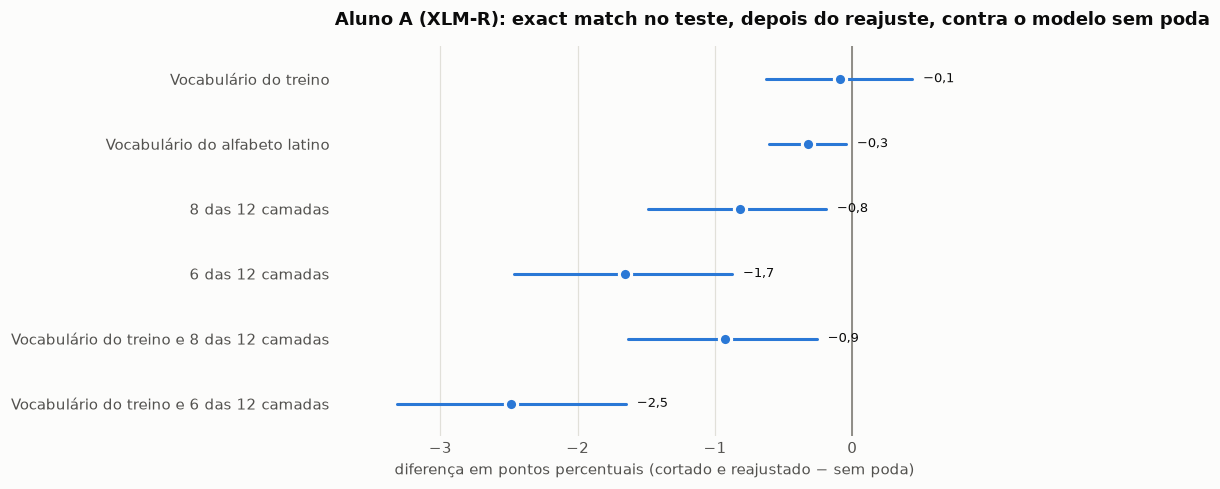

Aluno A (rótulos do Claude Haiku 5.5): exact match no teste, em % (intervalo de 95%); diferenças em pontos percentuais


,parâmetros,sistema no arquivo comum (MB),antes do reajuste,depois do reajuste,antes − sem poda,depois − sem poda,o que o reajuste recupera (depois − antes)
Vocabulário do treino,89.573.547,"359,0","53,6 (51,8 a 55,2)","53,7 (52,0 a 55,3)","−0,2 (−0,5 a +0,0)","−0,1 (−0,6 a +0,4)","+0,1 (−0,3 a +0,6)"
Vocabulário do alfabeto latino,172.555.947,"697,9","53,8 (52,1 a 55,4)","53,5 (51,8 a 55,1)","+0,0 (+0,0 a +0,0)","−0,3 (−0,6 a −0,0)","−0,3 (−0,6 a −0,0)"
8 das 12 camadas,249.233.067,"1.014,1","0,2 (0,1 a 0,3)","53,0 (51,3 a 54,7)","−53,6 (−55,2 a −51,9)","−0,8 (−1,5 a −0,2)","+52,8 (+51,1 a +54,4)"
6 das 12 camadas,235.057.323,"957,3","0,0 (0,0 a 0,1)","52,2 (50,4 a 53,8)","−53,8 (−55,4 a −52,0)","−1,7 (−2,5 a −0,9)","+52,1 (+50,4 a +53,8)"
Vocabulário do treino e 8 das 12 camadas,61.222.059,"245,6","0,2 (0,1 a 0,3)","52,9 (51,2 a 54,5)","−53,6 (−55,2 a −51,9)","−0,9 (−1,6 a −0,3)","+52,7 (+51,0 a +54,3)"
Vocabulário do treino e 6 das 12 camadas,47.046.315,"188,9","0,0 (0,0 a 0,1)","51,3 (49,6 a 53,0)","−53,8 (−55,4 a −52,0)","−2,5 (−3,3 a −1,6)","+51,3 (+49,6 a +52,9)"


Teto (rótulos humanos): exact match no teste, em % (intervalo de 95%); diferenças em pontos percentuais


,parâmetros,sistema no arquivo comum (MB),antes do reajuste,depois do reajuste,antes − sem poda,depois − sem poda,o que o reajuste recupera (depois − antes)
Vocabulário do treino,89.573.547,"359,0","65,8 (64,2 a 67,5)","65,8 (64,2 a 67,4)","−0,4 (−0,8 a −0,1)","−0,4 (−0,9 a +0,1)","+0,0 (−0,3 a +0,4)"
Vocabulário do alfabeto latino,172.555.947,"697,9","66,3 (64,7 a 67,9)","66,5 (64,8 a 68,0)","+0,0 (+0,0 a +0,0)","+0,2 (−0,2 a +0,5)","+0,2 (−0,2 a +0,5)"
8 das 12 camadas,249.233.067,"1.014,1","0,5 (0,4 a 0,7)","65,5 (63,9 a 67,1)","−65,8 (−67,4 a −64,2)","−0,8 (−1,5 a −0,1)","+65,0 (+63,4 a +66,6)"
6 das 12 camadas,235.057.323,"957,3","0,0 (0,0 a 0,1)","63,8 (62,1 a 65,5)","−66,2 (−67,8 a −64,6)","−2,5 (−3,4 a −1,7)","+63,7 (+62,1 a +65,4)"
Vocabulário do treino e 8 das 12 camadas,61.222.059,"245,6","0,5 (0,4 a 0,7)","65,0 (63,4 a 66,6)","−65,8 (−67,4 a −64,2)","−1,3 (−2,0 a −0,6)","+64,5 (+62,8 a +66,1)"
Vocabulário do treino e 6 das 12 camadas,47.046.315,"188,9","0,1 (0,0 a 0,1)","63,1 (61,5 a 64,8)","−66,2 (−67,8 a −64,6)","−3,2 (−4,0 a −2,3)","+63,1 (+61,4 a +64,8)"


Aluno A (rótulos do Claude Haiku 5.5): as três métricas no teste, depois do reajuste, contra o modelo sem poda


,Acurácia de intenção,F1 de entidades,Exact match
Vocabulário do treino,"+0,2 (−0,2 a +0,6)","−0,4 (−0,9 a +0,0)","−0,1 (−0,6 a +0,4)"
Vocabulário do alfabeto latino,"−0,1 (−0,4 a +0,1)","−0,0 (−0,3 a +0,2)","−0,3 (−0,6 a −0,0)"
8 das 12 camadas,"−0,3 (−0,9 a +0,2)","−0,8 (−1,4 a −0,2)","−0,8 (−1,5 a −0,2)"
6 das 12 camadas,"−1,1 (−1,7 a −0,4)","−1,9 (−2,6 a −1,1)","−1,7 (−2,5 a −0,9)"
Vocabulário do treino e 8 das 12 camadas,"−0,3 (−0,9 a +0,2)","−1,4 (−2,1 a −0,7)","−0,9 (−1,6 a −0,3)"
Vocabulário do treino e 6 das 12 camadas,"−1,5 (−2,2 a −0,9)","−2,7 (−3,5 a −1,9)","−2,5 (−3,3 a −1,6)"


**Leitura (teste, exact match).**

- **Aluno A:** depois do reajuste, não se distinguem do modelo sem poda em exact match: vocabulário do treino; ficam abaixo: vocabulário do alfabeto latino, 8 das 12 camadas, 6 das 12 camadas, vocabulário do treino e 8 das 12 camadas e vocabulário do treino e 6 das 12 camadas. Já sem reajuste, não se distinguem: vocabulário do treino e vocabulário do alfabeto latino.
- **Teto:** depois do reajuste, não se distinguem do modelo sem poda em exact match: vocabulário do treino e vocabulário do alfabeto latino; ficam abaixo: 8 das 12 camadas, 6 das 12 camadas, vocabulário do treino e 8 das 12 camadas e vocabulário do treino e 6 das 12 camadas. Já sem reajuste, não se distinguem: vocabulário do alfabeto latino.
- **Vocabulário do treino** (Aluno A): −0,2 (−0,5 a +0,0) antes do reajuste, −0,1 (−0,6 a +0,4) depois; o reajuste recupera +0,1 (−0,3 a +0,6).
- **Vocabulário do alfabeto latino** (Aluno A): +0,0 (+0,0 a +0,0) antes do reajuste, −0,3 (−0,6 a −0,0) depois; o reajuste recupera −0,3 (−0,6 a −0,0).
- **8 das 12 camadas** (Aluno A): −53,6 (−55,2 a −51,9) antes do reajuste, −0,8 (−1,5 a −0,2) depois; o reajuste recupera +52,8 (+51,1 a +54,4).
- **6 das 12 camadas** (Aluno A): −53,8 (−55,4 a −52,0) antes do reajuste, −1,7 (−2,5 a −0,9) depois; o reajuste recupera +52,1 (+50,4 a +53,8).
- **Vocabulário do treino e 8 das 12 camadas** (Aluno A): −53,6 (−55,2 a −51,9) antes do reajuste, −0,9 (−1,6 a −0,3) depois; o reajuste recupera +52,7 (+51,0 a +54,3).
- **Vocabulário do treino e 6 das 12 camadas** (Aluno A): −53,8 (−55,4 a −52,0) antes do reajuste, −2,5 (−3,3 a −1,6) depois; o reajuste recupera +51,3 (+49,6 a +52,9).


In [10]:
def quadro_das_pecas(m, variantes=PECAS, p="test"):
    tabela = quadro(m, variantes, p=p).drop(index="Sem poda")
    tabela.insert(0, "parâmetros", [n(exe[m][v][0]["meta"]["contagem"]["parametros"]) for v in variantes])
    tabela.insert(1, "sistema no arquivo comum (MB)", [mb(exe[m][v][0]["meta"]["bytes_em_disco"]) for v in variantes])
    return tabela


fig, ax = visual.diferencas_com_intervalo(
    {NOME[v]: trio(contra(PRINCIPAL, v).loc["exact_match"], "diferenca") for v in PECAS},
    f"{CURTO[PRINCIPAL]} (XLM-R): exact match no teste, depois do reajuste, contra o modelo sem poda", "diferença em pontos percentuais (cortado e reajustado − sem poda)",
)
visual.salvar(fig, PASTA, "pecas_inteiras")
plt.show()
for m in COMPLETOS:
    print(f"{MODELOS[m]['nome']}: exact match no teste, em % (intervalo de 95%); diferenças em pontos percentuais")
    display(quadro_das_pecas(m))
print(f"{MODELOS[PRINCIPAL]['nome']}: as três métricas no teste, depois do reajuste, contra o modelo sem poda")
display(pd.DataFrame({NOME[v]: {qualidade.NOMES[metrica]: com_intervalo(contra(PRINCIPAL, v).loc[metrica]) for metrica in TRES} for v in PECAS}).T)


def leitura_das_pecas(m):
    passam = [minusculo(NOME[v]) for v in PECAS if not contra(m, v).loc["exact_match", "ic_max"] < 0]
    caem = [minusculo(NOME[v]) for v in PECAS if contra(m, v).loc["exact_match", "ic_max"] < 0]
    sem_reajuste = [minusculo(NOME[v]) for v in PECAS if not contra(m, v, "antes").loc["exact_match", "ic_max"] < 0]
    return (f"depois do reajuste, não se distinguem do modelo sem poda em exact match: {lista(passam, 'nenhuma')}; ficam abaixo: {lista(caem, 'nenhuma')}. "
            f"Já sem reajuste, não se distinguem: {lista(sem_reajuste, 'nenhuma')}")


display(Markdown("**Leitura (teste, exact match).**\n\n" + "".join(f"- **{CURTO[m]}:** {leitura_das_pecas(m)}.\n" for m in COMPLETOS)
                 + "".join(f"- **{NOME[v]}** ({CURTO[PRINCIPAL]}): {com_intervalo(contra(PRINCIPAL, v, 'antes').loc['exact_match'])} antes do reajuste, "
                           f"{com_intervalo(contra(PRINCIPAL, v).loc['exact_match'])} depois; o reajuste recupera {com_intervalo(recupera(PRINCIPAL, v).loc['exact_match'])}.\n"
                           for v in PECAS)))

## 7. O orçamento do reajuste limita a recuperação?

Duas variantes do aluno A foram reajustadas também com 4 épocas (40% do treino, a proporção da Etapa 7), além das 10 da grade. A comparação é pareada: a mesma variante, as mesmas sementes, só o número de épocas muda. Este controle não entra na regra do que segue.

In [11]:
_orcamento = {}


def longo_contra_curto(v_curta, p="test"):
    """Comparação pareada: a variante com o reajuste da grade menos a mesma variante com o reajuste curto."""
    if (v_curta, p) not in _orcamento:
        _orcamento[v_curta, p] = qualidade.comparar_grupos(gabarito[p], grupo(PRINCIPAL, v_curta, p), grupo(PRINCIPAL, CURTAS[v_curta]["base"], p))
    return _orcamento[v_curta, p]


C, L = etapa10b.EPOCAS_CURTAS, EPOCAS
display(pd.DataFrame({
    NOME[CURTAS[v]["base"]]: {
        f"{C} épocas": valor_com_intervalo(medida(PRINCIPAL, v).loc["exact_match"]),
        f"{L} épocas": valor_com_intervalo(medida(PRINCIPAL, CURTAS[v]["base"]).loc["exact_match"]),
        **{f"{L} − {C} épocas, {qualidade.NOMES[metrica].lower()}": com_intervalo(longo_contra_curto(v).loc[metrica]) for metrica in TRES},
        f"{C} épocas − sem poda (exact match)": com_intervalo(contra(PRINCIPAL, v).loc["exact_match"]),
        f"{L} épocas − sem poda (exact match)": com_intervalo(contra(PRINCIPAL, CURTAS[v]["base"]).loc["exact_match"]),
        f"época escolhida ({C} épocas)": epocas_escolhidas(PRINCIPAL, v),
        f"época escolhida ({L} épocas)": epocas_escolhidas(PRINCIPAL, CURTAS[v]["base"]),
    }
    for v in CURTAS
}).T)


def leitura_do_orcamento(v):
    base = CURTAS[v]["base"]
    return (f"com {L} épocas em vez de {C}, o exact match fica {posicao(longo_contra_curto(v).loc['exact_match'])} ({com_intervalo(longo_contra_curto(v).loc['exact_match'])}); "
            f"contra o modelo sem poda, {com_intervalo(contra(PRINCIPAL, v).loc['exact_match'])} com {C} épocas e {com_intervalo(contra(PRINCIPAL, base).loc['exact_match'])} com {L}")


display(Markdown("**Leitura (teste).**\n\n" + "".join(f"- **{NOME[CURTAS[v]['base']]}:** {leitura_do_orcamento(v)}.\n" for v in CURTAS)))

,4 épocas,10 épocas,"10 − 4 épocas, acurácia de intenção","10 − 4 épocas, f1 de entidades","10 − 4 épocas, exact match",4 épocas − sem poda (exact match),10 épocas − sem poda (exact match),época escolhida (4 épocas),época escolhida (10 épocas)
"Magnitude, 90% de uma vez","18,1 (16,8 a 19,4)","36,7 (35,1 a 38,2)","+30,3 (+28,8 a +31,9)","+7,7 (+6,5 a +8,9)","+18,6 (+17,3 a +19,9)","−35,7 (−37,5 a −33,9)","−17,1 (−18,7 a −15,5)","4, 4, 4","9, 10, 10"
6 das 12 camadas,"14,7 (13,6 a 15,7)","52,2 (50,4 a 53,8)","+55,5 (+53,8 a +57,2)","−0,0 (−0,6 a +0,5)","+37,4 (+35,8 a +39,1)","−39,1 (−40,7 a −37,4)","−1,7 (−2,5 a −0,9)","4, 4, 4","9, 9, 10"


**Leitura (teste).**

- **Magnitude, 90% de uma vez:** com 10 épocas em vez de 4, o exact match fica acima (+18,6 (+17,3 a +19,9)); contra o modelo sem poda, −35,7 (−37,5 a −33,9) com 4 épocas e −17,1 (−18,7 a −15,5) com 10.
- **6 das 12 camadas:** com 10 épocas em vez de 4, o exact match fica acima (+37,4 (+35,8 a +39,1)); contra o modelo sem poda, −39,1 (−40,7 a −37,4) com 4 épocas e −1,7 (−2,5 a −0,9) com 10.


## 8. O XLM-R ao lado da rede do zero

A mesma poda por magnitude, de uma vez, no aluno A dos dois caminhos: o da rede do zero (Etapa 7) e o do XLM-R (aqui). Cada um é comparado com o **seu próprio** modelo sem poda, no teste. As duas curvas ficam lado a lado; não há teste entre elas, porque mudam juntos a rede, o tamanho e o orçamento do reajuste.

Comparações da Etapa 7 lidas: ['antes − sem poda', 'depois − antes', 'depois − sem poda', 'gradual − de uma vez']


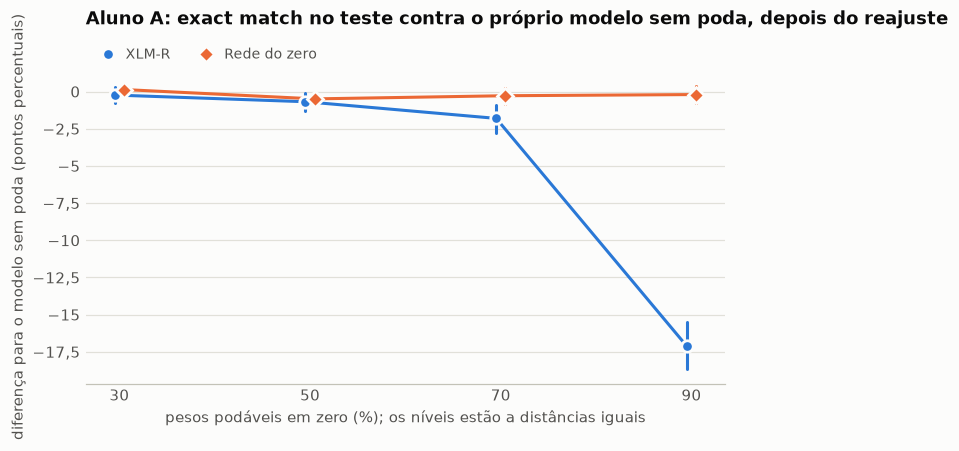

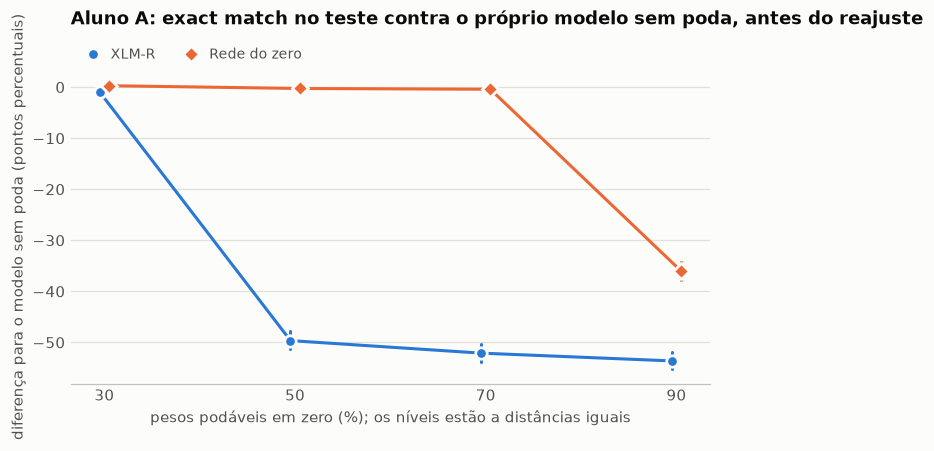

,"XLM-R, antes do reajuste","Rede do zero, antes do reajuste","XLM-R, depois do reajuste","Rede do zero, depois do reajuste"
30%,"−1,0 (−2,0 a +0,0)","+0,3 (+0,0 a +0,5)","−0,2 (−0,8 a +0,3)","+0,1 (−0,2 a +0,5)"
50%,"−49,7 (−51,4 a −47,8)","−0,3 (−0,7 a +0,2)","−0,7 (−1,3 a −0,1)","−0,5 (−0,9 a −0,1)"
70%,"−52,1 (−53,8 a −50,3)","−0,4 (−1,1 a +0,2)","−1,8 (−2,8 a −0,9)","−0,3 (−0,8 a +0,2)"
90%,"−53,6 (−55,3 a −51,9)","−36,0 (−37,7 a −34,3)","−17,1 (−18,7 a −15,5)","−0,2 (−0,8 a +0,4)"



**Leitura (aluno A, teste, exact match, diferença para o próprio modelo sem poda).**

- **Sem reajuste**, ficam distinguivelmente abaixo: o XLM-R em 50%, 70% e 90%; a rede do zero em 90%.
- **Com reajuste**: o XLM-R em 50%, 70% e 90%; a rede do zero em 50%.
- **Em 90%**: o XLM-R fica a −17,1 (−18,7 a −15,5) do seu modelo sem poda, e a rede do zero, a −0,2 (−0,8 a +0,4).
- **O que não é igual nos dois lados:** na rede do zero a poda alcança 98,7% dos parâmetros (a tabela de features entra); no XLM-R, 30,6% (só o corpo). O reajuste teve 30 épocas lá (37,5% do treino) e 10 aqui (o treino inteiro).


In [12]:
do_zero = pd.read_csv(ENTREGAS / "07_poda" / "comparacoes.csv")
do_zero = do_zero[(do_zero["modelo"] == "aluno_a") & (do_zero["particao"] == "test") & (do_zero["metrica"] == "exact_match")]
linha_do_zero = lambda s, comparacao: do_zero[(do_zero["variante"] == f"magnitude_{s}") & (do_zero["comparacao"] == comparacao)].iloc[0]
print("Comparações da Etapa 7 lidas:", sorted(do_zero["comparacao"].unique()))

lado_a_lado = {}
for momento, comparacao in (("depois", "depois − sem poda"), ("antes", "antes − sem poda")):
    lado_a_lado[momento] = {
        "XLM-R": {s: trio(contra(PRINCIPAL, DE_UMA_VEZ[s], momento).loc["exact_match"], "diferenca") for s in NIVEIS},
        "Rede do zero": {s: trio(linha_do_zero(s, comparacao), "diferenca") for s in NIVEIS},
    }
    fig, ax = curva(lado_a_lado[momento], f"Aluno A: exact match no teste contra o próprio modelo sem poda, {momento} do reajuste",
                    "pesos podáveis em zero (%); os níveis estão a distâncias iguais", "diferença para o modelo sem poda (pontos percentuais)", niveis=True)
    visual.salvar(fig, PASTA, f"xlmr_e_rede_do_zero_{momento}")
    plt.show()

em_texto = lambda t: f"{dif(t[0] / 100)} ({dif(t[1] / 100)} a {dif(t[2] / 100)})"
display(pd.DataFrame({
    f"{s}%": {f"{rede}, {momento} do reajuste": em_texto(lado_a_lado[momento][rede][s]) for momento in ("antes", "depois") for rede in ("XLM-R", "Rede do zero")}
    for s in NIVEIS
}).T)
cai = lambda rede, momento: [f"{s}%" for s in NIVEIS if lado_a_lado[momento][rede][s][2] < 0]
display(Markdown(f"""
**Leitura (aluno A, teste, exact match, diferença para o próprio modelo sem poda).**

- **Sem reajuste**, ficam distinguivelmente abaixo: o XLM-R em {lista(cai("XLM-R", "antes"), "nenhum nível")}; a rede do zero em {lista(cai("Rede do zero", "antes"), "nenhum nível")}.
- **Com reajuste**: o XLM-R em {lista(cai("XLM-R", "depois"), "nenhum nível")}; a rede do zero em {lista(cai("Rede do zero", "depois"), "nenhum nível")}.
- **Em 90%**: o XLM-R fica a {em_texto(lado_a_lado["depois"]["XLM-R"][90])} do seu modelo sem poda, e a rede do zero, a {em_texto(lado_a_lado["depois"]["Rede do zero"][90])}.
- **O que não é igual nos dois lados:** na rede do zero a poda alcança 98,7% dos parâmetros (a tabela de features entra); no XLM-R, {pts(PODAVEIS / total)}% (só o corpo). O reajuste teve 30 épocas lá (37,5% do treino) e {EPOCAS} aqui (o treino inteiro).
"""))

## 9. O que muda de verdade: parâmetros, bytes e milissegundos

Tamanho e latência são medidos nos arquivos gravados e nos modelos carregados (semente 0), não estimados. O tamanho vem em três formatos: o **arquivo comum** (grava todos os pesos, zeros inclusive), o arquivo comum **com zip** e o **arquivo esparso** (um bit por posição e só os pesos diferentes de zero). A **rede** é contada separada do **tokenizador e das configurações**, sem os quais o sistema não recebe texto. A latência é o p50 em CPU, com 1 thread, uma consulta por vez, do texto à resposta.

Aluno A (rótulos do Claude Haiku 5.5), semente 0. Tamanhos em MB; latência p50 em ms, 1 thread de CPU


,parâmetros,diferentes de zero,rede: arquivo comum,rede: com zip,rede: arquivo esparso,tokenizador e configurações,sistema: arquivo comum,latência,"latência, execução esparsa"
variante,,,,,,,,,
Sem poda,277.584.555,277.583.755,"1.110,4","828,1","1.110,4","17,1","1.127,5","35,9",—
"Magnitude, 30% de uma vez",277.584.555,252.103.363,"1.110,4","759,8","1.019,2","17,1","1.127,5","37,0","88,4"
"Magnitude, 50% de uma vez",277.584.555,235.116.427,"1.110,4","704,0","951,2","17,1","1.127,5","37,6","63,4"
"Magnitude, 70% de uma vez",277.584.555,218.129.491,"1.110,4","644,0","883,3","17,1","1.127,5","36,9","40,6"
"Magnitude, 90% de uma vez",277.584.555,201.142.555,"1.110,4","576,4","815,3","17,1","1.127,5","36,7","17,2"
"Magnitude, 30% gradual",277.584.555,252.103.363,"1.110,4","759,8","1.019,2","17,1","1.127,5","37,1",—
"Magnitude, 50% gradual",277.584.555,235.116.427,"1.110,4","703,9","951,2","17,1","1.127,5","37,0",—
"Magnitude, 70% gradual",277.584.555,218.129.491,"1.110,4","643,9","883,3","17,1","1.127,5","37,4","40,4"
"Magnitude, 90% gradual",277.584.555,201.142.555,"1.110,4","576,4","815,3","17,1","1.127,5","37,1",—


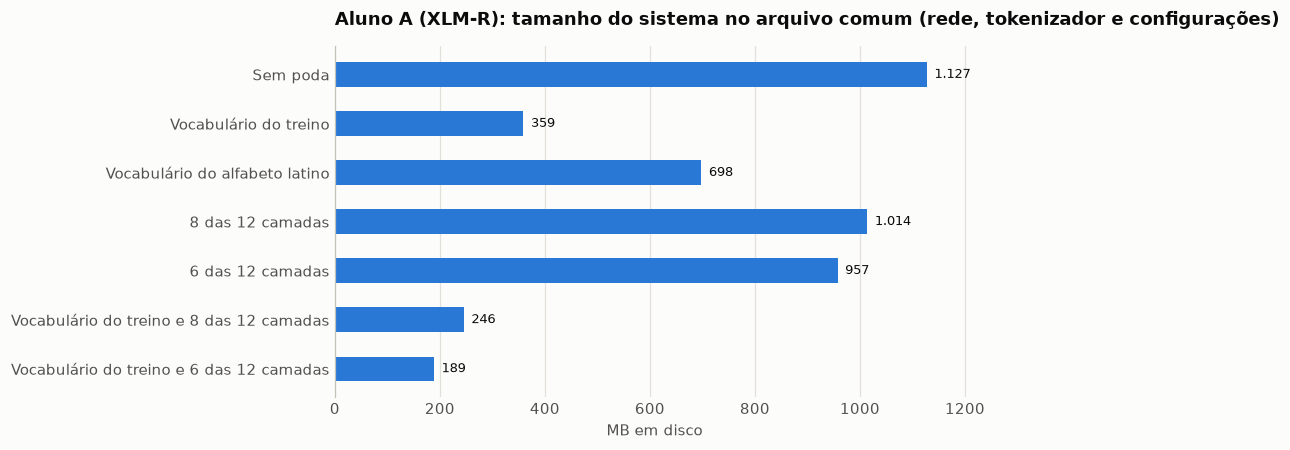

In [13]:
tamanhos = etapa10b.medir_tamanhos()      # o que já foi medido pelo comando `tamanhos` só é lido
latencias = {m: etapa10b.carregar_latencias(m) for m in MODELOS}


def latencia(m, v, execucao="comum"):
    """O p50 da variante, em ms, na execução comum ou na esparsa. None se não foi medida."""
    for grupo_medido in latencias[m].values():
        if grupo_medido["execucao"].startswith(execucao) and v in grupo_medido["resumo"]:
            return grupo_medido["resumo"][v]["latencia_p50_ms"]
    return None


def custo(m, v):
    """A linha de custo de uma variante (`v=None`: o modelo de partida)."""
    medido = tamanhos[m, v or etapa10b.DE_PARTIDA]
    rede, resto, sistema = (medido["bytes"][parte] for parte in ("rede", "tokenizador_e_configuracao", "sistema"))
    return {
        "modelo": m, "variante": v or "de_partida", "nome": "Sem poda" if v is None else NOME[v],
        "parametros": medido["parametros"], "nao_nulos": medido["nao_nulos"], "esparsidade_do_corpo": medido["esparsidade"],
        "linhas_da_tabela": medido["parametros_por_parte"]["A. Tabela de subtokens"] // 768,
        "rede_arquivo_comum": rede["arquivo_comum"], "rede_com_zip": rede["arquivo_comum_com_zip"], "rede_arquivo_esparso": rede["arquivo_esparso"],
        "tokenizador_e_configuracao": resto["arquivo_comum"],
        "sistema_arquivo_comum": sistema["arquivo_comum"], "sistema_com_zip": sistema["arquivo_comum_com_zip"], "sistema_arquivo_esparso": sistema["arquivo_esparso"],
        "latencia_p50_ms": latencia(m, v or etapa10b.DE_PARTIDA), "latencia_esparsa_p50_ms": latencia(m, v, "esparsa") if v else None,
    }


com_pesos = lambda m: [v for v in ORDEM if (m, v) in tamanhos]      # o controle não guarda pesos: o custo dele é o do modelo sem poda
eficiencia = pd.DataFrame([custo(m, v) for m in MODELOS for v in [None, *(v for v in ORDEM if (m, v) in tamanhos)]])
ms = lambda x: "—" if x is None or pd.isna(x) else num(x, 1)
vista = eficiencia[eficiencia["modelo"] == PRINCIPAL]
print(f"{MODELOS[PRINCIPAL]['nome']}, semente 0. Tamanhos em MB; latência p50 em ms, 1 thread de CPU")
display(pd.DataFrame([
    {
        "variante": l["nome"], "parâmetros": n(l["parametros"]), "diferentes de zero": n(l["nao_nulos"]),
        "rede: arquivo comum": mb(l["rede_arquivo_comum"]), "rede: com zip": mb(l["rede_com_zip"]), "rede: arquivo esparso": mb(l["rede_arquivo_esparso"]),
        "tokenizador e configurações": mb(l["tokenizador_e_configuracao"]), "sistema: arquivo comum": mb(l["sistema_arquivo_comum"]),
        "latência": ms(l["latencia_p50_ms"]), "latência, execução esparsa": ms(l["latencia_esparsa_p50_ms"]),
    }
    for _, l in vista.iterrows()
]).set_index("variante"))

fig, ax = visual.barras_em_ordem(
    {l["nome"]: l["sistema_arquivo_comum"] / 1e6 for _, l in vista.iterrows() if l["variante"] == "de_partida" or l["variante"] in PECAS},
    f"{CURTO[PRINCIPAL]} (XLM-R): tamanho do sistema no arquivo comum (rede, tokenizador e configurações)", "MB em disco", formato=lambda x: n(round(x)),
)
visual.salvar(fig, PASTA, "tamanho_em_disco")
plt.show()

In [14]:
c = lambda v: vista[vista["variante"] == (v or "de_partida")].iloc[0]
base, topo = c(None), c(DE_UMA_VEZ[max(NIVEIS)])
menor = min((c(v) for v in PECAS), key=lambda l: l["sistema_arquivo_comum"])
medidas_de_latencia = vista.dropna(subset=["latencia_p50_ms"])
display(Markdown(f"""
**Leitura ({CURTO[PRINCIPAL]}, semente 0).**

- **Com os pesos soltos**, o número de parâmetros não muda e o arquivo comum também não: com {max(NIVEIS)}% do corpo em zero, a rede ocupa {mb(topo['rede_arquivo_comum'])} MB, contra {mb(base['rede_arquivo_comum'])} MB sem poda. Mudam os diferentes de zero ({n(topo['nao_nulos'])}, contra {n(base['nao_nulos'])}) e o tamanho num formato que aproveite os zeros: {mb(topo['rede_com_zip'])} MB com zip e {mb(topo['rede_arquivo_esparso'])} MB no arquivo esparso. O piso é a tabela de subtokens, que a poda por magnitude não toca: {mb(partes['A. Tabela de subtokens'] * 4)} MB.
- **Com as peças inteiras**, o arquivo comum diminui sem formato especial. O menor sistema é {minusculo(menor['nome'])}: {mb(menor['sistema_arquivo_comum'])} MB ({n(menor['parametros'])} parâmetros), contra {mb(base['sistema_arquivo_comum'])} MB ({num(base['sistema_arquivo_comum'] / menor['sistema_arquivo_comum'], 1)} vezes menor).
- **O tokenizador conta.** Sem poda, o tokenizador e as configurações ocupam {mb(base['tokenizador_e_configuracao'])} MB; com o vocabulário do treino, {mb(c('vocabulario_treino')['tokenizador_e_configuracao'])} MB.
- **Latência** (medida em {len(medidas_de_latencia)} das {len(vista)} linhas): {"; ".join(f"{minusculo(l['nome'])}: {ms(l['latencia_p50_ms'])} ms" for _, l in medidas_de_latencia.iterrows()) or "ainda não medida"}.
"""))


**Leitura (Aluno A, semente 0).**

- **Com os pesos soltos**, o número de parâmetros não muda e o arquivo comum também não: com 90% do corpo em zero, a rede ocupa 1.110,4 MB, contra 1.110,4 MB sem poda. Mudam os diferentes de zero (201.142.555, contra 277.583.755) e o tamanho num formato que aproveite os zeros: 576,4 MB com zip e 815,3 MB no arquivo esparso. O piso é a tabela de subtokens, que a poda por magnitude não toca: 768,0 MB.
- **Com as peças inteiras**, o arquivo comum diminui sem formato especial. O menor sistema é vocabulário do treino e 6 das 12 camadas: 188,9 MB (47.046.315 parâmetros), contra 1.127,5 MB (6,0 vezes menor).
- **O tokenizador conta.** Sem poda, o tokenizador e as configurações ocupam 17,1 MB; com o vocabulário do treino, 0,7 MB.
- **Latência** (medida em 15 das 15 linhas): sem poda: 35,9 ms; magnitude, 30% de uma vez: 37,0 ms; magnitude, 50% de uma vez: 37,6 ms; magnitude, 70% de uma vez: 36,9 ms; magnitude, 90% de uma vez: 36,7 ms; magnitude, 30% gradual: 37,1 ms; magnitude, 50% gradual: 37,0 ms; magnitude, 70% gradual: 37,4 ms; magnitude, 90% gradual: 37,1 ms; vocabulário do treino: 36,0 ms; vocabulário do alfabeto latino: 36,1 ms; 8 das 12 camadas: 24,4 ms; 6 das 12 camadas: 19,2 ms; vocabulário do treino e 8 das 12 camadas: 24,4 ms; vocabulário do treino e 6 das 12 camadas: 18,3 ms.


## 10. O que segue para a quantização

A regra da seção 2, aplicada em `dev` com os rótulos humanos. É a única decisão da etapa. O aluno B2 não tem regra própria: recebe a principal e a secundária do aluno A, e a tabela dele só mostra como elas se saem nele.

In [15]:
candidatos = lambda m, variantes: {
    v: {"em_dev": grupo(m, v, "dev"), "nao_nulos": exe[m][v][0]["meta"]["contagem"]["nao_nulos"], "bytes": exe[m][v][0]["meta"]["bytes_em_disco"]}
    for v in variantes
}
decisoes = {m: etapa10b.quem_segue(gabarito["dev"], sem_poda[m]["dev"], candidatos(m, PODADAS)) for m in COMPLETOS}
gravada = etapa10b.seguem_do_principal()      # o que a onda decidiu para o aluno principal, e que definiu as execuções do outro aluno
assert (gravada["principal"], gravada["secundaria"]) == (decisoes[PRINCIPAL]["principal"], decisoes[PRINCIPAL]["secundaria"]), "A regra refeita aqui não dá o que a onda gravou."
for m in DEPENDENTES:
    do_principal = decisoes[PRINCIPAL]
    tabela = etapa10b.quem_segue(gabarito["dev"], sem_poda[m]["dev"], candidatos(m, VARIANTES_DE[m]))["tabela"]
    decisoes[m] = {"principal": do_principal["principal"], "secundaria": do_principal["secundaria"], "seguem": list(do_principal["seguem"]), "tabela": tabela}

for m in MODELOS:
    tabela = decisoes[m]["tabela"]
    papel = {decisoes[m]["principal"]: "principal", decisoes[m]["secundaria"]: "secundária"}
    print(f"{MODELOS[m]['nome']}: exact match em dev (rótulos humanos), depois do reajuste, contra o modelo sem poda")
    display(pd.DataFrame([
        {
            "variante": NOME[v], "sistema no arquivo comum (MB)": mb(l["bytes"]), "diferentes de zero": n(l["nao_nulos"]),
            "podado": pts(l["podado"]), "podado − sem poda": com_intervalo(l), "passa": "sim" if l["passa"] else "não", "segue como": papel.get(v, ""),
            "no teste: podado − sem poda": com_intervalo(contra(m, v).loc["exact_match"]),
            "abaixo no teste": "sim" if contra(m, v).loc["exact_match", "ic_max"] < 0 else "não",
        }
        for v, l in tabela.iterrows()
    ]).set_index("variante"))


def discordam(m):
    """Onde dev e teste não dizem o mesmo: (passam em dev e ficam abaixo no teste, não passam em dev e não se distinguem no teste)."""
    tabela = decisoes[m]["tabela"]
    abaixo_no_teste = lambda v: contra(m, v).loc["exact_match", "ic_max"] < 0
    return ([v for v in tabela.index if tabela.loc[v, "passa"] and abaixo_no_teste(v)],
            [v for v in tabela.index if not tabela.loc[v, "passa"] and not abaixo_no_teste(v)])


def leitura_de_dev_e_teste(m):
    so_dev, so_teste = discordam(m)
    com_numeros = lambda v: f"{minusculo(NOME[v])} ({com_intervalo(decisoes[m]['tabela'].loc[v])} em dev, {com_intervalo(contra(m, v).loc['exact_match'])} no teste)"
    return (f"passam em dev e ficam distinguivelmente abaixo no teste: {lista([com_numeros(v) for v in so_dev], 'nenhuma')}; "
            f"não passam em dev e não se distinguem no teste: {lista([com_numeros(v) for v in so_teste], 'nenhuma')}")


def descricao(m, v):
    if v is None:
        return "nenhuma (segue o modelo sem poda)"
    l = decisoes[m]["tabela"].loc[v]
    return f"{minusculo(NOME[v])}: {com_intervalo(l)} em dev, {mb(l['bytes'])} MB no arquivo comum, {n(l['nao_nulos'])} parâmetros diferentes de zero"


display(Markdown("**Leitura.**\n\n" + "".join(
    f"- **{CURTO[m]}:** principal: {descricao(m, decisoes[m]['principal'])}; secundária: {descricao(m, decisoes[m]['secundaria'])}."
    + ("" if m in COMPLETOS else " (As variantes são as do aluno principal; "
       + lista([f"{minusculo(NOME[v])} {'passa' if decisoes[m]['tabela'].loc[v, 'passa'] else 'NÃO passa'} na regra aplicada a ele" for v in decisoes[m]["seguem"]], "nenhuma") + ".)")
    + "\n" for m in MODELOS)
    + "\n**Dev e teste dizem o mesmo?** A regra só olha `dev`. O teste não decide nada, mas mostra onde a decisão é frágil.\n\n"
    + "".join(f"- **{CURTO[m]}:** {leitura_de_dev_e_teste(m)}.\n" for m in MODELOS)))

Aluno A (rótulos do Claude Haiku 5.5): exact match em dev (rótulos humanos), depois do reajuste, contra o modelo sem poda


,sistema no arquivo comum (MB),diferentes de zero,podado,podado − sem poda,passa,segue como,no teste: podado − sem poda,abaixo no teste
variante,,,,,,,,
Vocabulário do treino,"359,0",89.572.779,"54,0","−0,4 (−1,0 a +0,3)",sim,principal,"−0,1 (−0,6 a +0,4)",não
Vocabulário do alfabeto latino,"697,9",172.555.169,"54,4","+0,0 (−0,3 a +0,3)",sim,,"−0,3 (−0,6 a −0,0)",sim
8 das 12 camadas,"1.014,1",249.232.267,"53,1","−1,2 (−2,0 a −0,5)",não,,"−0,8 (−1,5 a −0,2)",sim
6 das 12 camadas,"957,3",235.056.523,"52,1","−2,3 (−3,3 a −1,3)",não,,"−1,7 (−2,5 a −0,9)",sim
Vocabulário do treino e 8 das 12 camadas,"245,6",61.221.291,"52,9","−1,5 (−2,4 a −0,7)",não,,"−0,9 (−1,6 a −0,3)",sim
Vocabulário do treino e 6 das 12 camadas,"188,9",47.045.547,"51,7","−2,6 (−3,7 a −1,6)",não,,"−2,5 (−3,3 a −1,6)",sim
"Magnitude, 90% de uma vez","1.127,5",201.142.555,"38,9","−15,4 (−17,3 a −13,6)",não,,"−17,1 (−18,7 a −15,5)",sim
"Magnitude, 90% gradual","1.127,5",201.142.555,"42,7","−11,6 (−13,5 a −9,9)",não,,"−12,5 (−13,9 a −11,1)",sim
"Magnitude, 70% de uma vez","1.127,5",218.129.491,"52,6","−1,8 (−2,8 a −0,7)",não,,"−1,8 (−2,8 a −0,9)",sim


Aluno B2 (logits do Qwen3-8B): exact match em dev (rótulos humanos), depois do reajuste, contra o modelo sem poda


,sistema no arquivo comum (MB),diferentes de zero,podado,podado − sem poda,passa,segue como,no teste: podado − sem poda,abaixo no teste
variante,,,,,,,,
Vocabulário do treino,"359,0",89.572.779,"46,8","−0,4 (−0,9 a +0,0)",sim,principal,"−1,0 (−1,4 a −0,6)",sim
"Magnitude, 70% gradual","1.127,5",218.129.491,"46,8","−0,4 (−1,5 a +0,6)",sim,secundária,"−0,5 (−1,4 a +0,4)",não


Teto (rótulos humanos): exact match em dev (rótulos humanos), depois do reajuste, contra o modelo sem poda


,sistema no arquivo comum (MB),diferentes de zero,podado,podado − sem poda,passa,segue como,no teste: podado − sem poda,abaixo no teste
variante,,,,,,,,
Vocabulário do treino,"359,0",89.572.779,"66,7","−0,1 (−0,7 a +0,4)",sim,principal,"−0,4 (−0,9 a +0,1)",não
Vocabulário do alfabeto latino,"697,9",172.555.169,"66,8","+0,0 (−0,4 a +0,4)",sim,,"+0,2 (−0,2 a +0,5)",não
8 das 12 camadas,"1.014,1",249.232.267,"65,7","−1,1 (−1,9 a −0,2)",não,,"−0,8 (−1,5 a −0,1)",sim
6 das 12 camadas,"957,3",235.056.523,"63,4","−3,4 (−4,6 a −2,4)",não,,"−2,5 (−3,4 a −1,7)",sim
Vocabulário do treino e 8 das 12 camadas,"245,6",61.221.291,"65,4","−1,4 (−2,2 a −0,6)",não,,"−1,3 (−2,0 a −0,6)",sim
Vocabulário do treino e 6 das 12 camadas,"188,9",47.045.547,"62,9","−3,9 (−5,0 a −2,8)",não,,"−3,2 (−4,0 a −2,3)",sim
"Magnitude, 90% de uma vez","1.127,5",201.142.555,"43,0","−23,8 (−25,8 a −21,9)",não,,"−25,4 (−26,9 a −23,8)",sim
"Magnitude, 90% gradual","1.127,5",201.142.555,"46,7","−20,1 (−22,0 a −18,3)",não,,"−21,1 (−22,6 a −19,6)",sim
"Magnitude, 70% de uma vez","1.127,5",218.129.491,"62,1","−4,7 (−5,9 a −3,5)",não,,"−4,7 (−5,7 a −3,8)",sim


**Leitura.**

- **Aluno A:** principal: vocabulário do treino: −0,4 (−1,0 a +0,3) em dev, 359,0 MB no arquivo comum, 89.572.779 parâmetros diferentes de zero; secundária: magnitude, 70% gradual: −0,9 (−1,8 a +0,0) em dev, 1.127,5 MB no arquivo comum, 218.129.491 parâmetros diferentes de zero.
- **Aluno B2:** principal: vocabulário do treino: −0,4 (−0,9 a +0,0) em dev, 359,0 MB no arquivo comum, 89.572.779 parâmetros diferentes de zero; secundária: magnitude, 70% gradual: −0,4 (−1,5 a +0,6) em dev, 1.127,5 MB no arquivo comum, 218.129.491 parâmetros diferentes de zero. (As variantes são as do aluno principal; vocabulário do treino passa na regra aplicada a ele e magnitude, 70% gradual passa na regra aplicada a ele.)
- **Teto:** principal: vocabulário do treino: −0,1 (−0,7 a +0,4) em dev, 359,0 MB no arquivo comum, 89.572.779 parâmetros diferentes de zero; secundária: magnitude, 50% de uma vez: −0,6 (−1,4 a +0,2) em dev, 1.127,5 MB no arquivo comum, 235.116.427 parâmetros diferentes de zero.

**Dev e teste dizem o mesmo?** A regra só olha `dev`. O teste não decide nada, mas mostra onde a decisão é frágil.

- **Aluno A:** passam em dev e ficam distinguivelmente abaixo no teste: vocabulário do alfabeto latino (+0,0 (−0,3 a +0,3) em dev, −0,3 (−0,6 a −0,0) no teste), magnitude, 70% gradual (−0,9 (−1,8 a +0,0) em dev, −0,8 (−1,6 a −0,0) no teste) e magnitude, 50% de uma vez (−0,4 (−1,2 a +0,3) em dev, −0,7 (−1,3 a −0,1) no teste); não passam em dev e não se distinguem no teste: nenhuma.
- **Aluno B2:** passam em dev e ficam distinguivelmente abaixo no teste: vocabulário do treino (−0,4 (−0,9 a +0,0) em dev, −1,0 (−1,4 a −0,6) no teste); não passam em dev e não se distinguem no teste: nenhuma.
- **Teto:** passam em dev e ficam distinguivelmente abaixo no teste: magnitude, 50% de uma vez (−0,6 (−1,4 a +0,2) em dev, −0,9 (−1,5 a −0,2) no teste) e magnitude, 30% gradual (−0,2 (−1,0 a +0,5) em dev, −0,9 (−1,6 a −0,3) no teste); não passam em dev e não se distinguem no teste: nenhuma.


## 11. Entrega

In [16]:
relativo_a_raiz = lambda caminho: str(Path(caminho).relative_to(RAIZ))


def copiar(origem, destino):
    """Copia a pasta sem ocupar o disco duas vezes quando dá (ligação entre arquivos); senão, copia de verdade."""
    try:
        shutil.copytree(origem, destino, copy_function=os.link)
    except OSError:
        shutil.rmtree(destino, ignore_errors=True)
        shutil.copytree(origem, destino)


# 1. Os modelos que seguem, com as respostas e os históricos
for antiga in ("modelos", "previsoes", "historicos"):
    if (PASTA / antiga).exists():
        shutil.rmtree(PASTA / antiga)
(PASTA / "historicos").mkdir()
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
reproduz, mantem_os_zeros = [], []
for m in MODELOS:
    for v in decisoes[m]["seguem"]:
        for i, semente in enumerate(SEMENTES):
            destino = PASTA / "modelos" / m / v / f"semente_{semente}"
            copiar(exe[m][v][i]["pasta"] / "modelo", destino)
            entregue = SistemaEncoder.carregar(destino, dispositivo)
            reproduz.append(np.mean([a == b for a, b in zip(entregue.prever(list(teste["utt"])), exe[m][v][i]["previsoes"]["test"])]))
            if v in SOLTAS:
                contagem = poda_encoder.contar(entregue.modelo)
                mantem_os_zeros.append(contagem["podaveis"] - contagem["nao_nulos_podaveis"] == zeros_de(exe[m][v][i]))
            del entregue
            for particao, ids in (("dev", dev["id"]), ("test", teste["id"])):
                salvar_previsoes(PASTA / "previsoes" / f"{m}__{v}_semente_{semente}_{particao}.parquet", ids, exe[m][v][i]["previsoes"][particao])
    for v in exe[m]:
        for semente, e in zip(SEMENTES, exe[m][v]):
            e["historico"].to_csv(PASTA / "historicos" / f"{m}__{v}_semente_{semente}.csv", index=False)

# 2. A tabela de resultados: o modelo sem poda e cada variante, antes e depois do reajuste, em dev e no teste
linhas_resultado = []
for m in MODELOS:
    for p in ("dev", "test"):
        linhas_resultado.append(resultados.registrar_grupo(f"{m}: sem poda", p, gabarito[p], sem_poda[m][p], modelo=m, variante="de_partida", momento="sem poda"))
        for v in exe[m]:
            medido = tamanhos.get((m, v))
            extras = {"parametros": medido["parametros"], "bytes_em_disco": medido["bytes"]["sistema"]["arquivo_comum"]} if medido else {}
            linhas_resultado.append(resultados.registrar_grupo(f"{m}: {NOME[v]}", p, gabarito[p], grupo(m, v, p), modelo=m, variante=v, momento="depois do reajuste", **extras))
            if f"{p}_antes" in exe[m][v][0]["previsoes"] and v != "sem_poda":
                linhas_resultado.append(resultados.registrar_grupo(f"{m}: {NOME[v]}, sem reajuste", p, gabarito[p], grupo(m, v, p, "antes"),
                                                                    modelo=m, variante=v, momento="antes do reajuste", **extras))
resultados.salvar(linhas_resultado, PASTA)

# 3. Todas as comparações pareadas da lista fechada
comparacoes = {}
for m in MODELOS:
    for p in ("dev", "test"):
        for v in exe[m]:
            comparacoes[m, v, "depois − sem poda", p] = contra(m, v, "depois", p)
            if f"{p}_antes" in exe[m][v][0]["previsoes"] and v != "sem_poda":
                comparacoes[m, v, "antes − sem poda", p] = contra(m, v, "antes", p)
                comparacoes[m, v, "depois − antes", p] = recupera(m, v, p)
        if m in COMPLETOS:
            for s in NIVEIS:
                comparacoes[m, GRADUAL[s], "gradual − de uma vez", p] = gradual_contra_de_uma_vez(m, s, p)
    for v in CURTAS:
        for p in ("dev", "test"):
            comparacoes[PRINCIPAL, CURTAS[v]["base"], f"{EPOCAS} épocas − {etapa10b.EPOCAS_CURTAS} épocas", p] = longo_contra_curto(v, p)
pd.concat(comparacoes, names=["modelo", "variante", "comparacao", "particao", "metrica"]).to_csv(PASTA / "comparacoes.csv")
eficiencia.to_csv(PASTA / "eficiencia.csv", index=False)
diagnostico.to_csv(PASTA / "corte_do_vocabulario.csv")
for guardado in ("piloto.json", "latencia.sh", "segue_do_principal.json"):
    shutil.copy(etapa10b.pasta_da_etapa() / guardado, PASTA / guardado)
(PASTA / "latencia").mkdir(exist_ok=True)
for medido in sorted((etapa10b.pasta_da_etapa() / "latencia").glob("*.json")):
    shutil.copy(medido, PASTA / "latencia" / medido.name)


# 4. A tabela principal: cada variante de cada modelo de partida, no teste
def linha_principal(m, v):
    valores = medida(m, v)
    tem_custo = (m, v or etapa10b.DE_PARTIDA) in tamanhos
    k = custo(m, v) if tem_custo else custo(m, None) if v == "sem_poda" else {}
    papel = {decisoes[m]["principal"]: "principal", decisoes[m]["secundaria"]: "secundaria"}.get(v, "") if v else ""
    return {
        "modelo": m, "variante": v or "de_partida", "nome": "Sem poda" if v is None else NOME[v], "papel": papel,
        **{metrica: valores.loc[metrica, "valor"] for metrica in TRES},
        "exact_match_antes": medida(m, v, "antes").loc["exact_match", "valor"] if v and v != "sem_poda" and tem_antes(v) else None,
        **({f"{c}_exact_match": contra(m, v).loc["exact_match", c] for c in ("diferenca", "ic_min", "ic_max")} if v else {}),
        **{chave: k.get(chave) for chave in ("parametros", "nao_nulos", "rede_arquivo_comum", "rede_com_zip", "rede_arquivo_esparso", "tokenizador_e_configuracao",
                                             "sistema_arquivo_comum", "sistema_com_zip", "sistema_arquivo_esparso", "latencia_p50_ms", "latencia_esparsa_p50_ms")},
    }


tabela_principal = pd.DataFrame([linha_principal(m, v) for m in MODELOS for v in [None, *(x for x in [*ORDEM, *CURTAS] if x in exe[m])]])
tabela_principal.to_csv(PASTA / "tabela_principal.csv", index=False)


# 5. A decisão, no formato da Etapa 7 (é o que a Etapa 10c lê)
def bytes_de(k):
    return {
        "arquivo_comum": int(k["sistema_arquivo_comum"]), "arquivo_comum_com_zip": int(k["sistema_com_zip"]), "arquivo_esparso": int(k["sistema_arquivo_esparso"]),
        "so_a_rede": {"arquivo_comum": int(k["rede_arquivo_comum"]), "arquivo_comum_com_zip": int(k["rede_com_zip"]), "arquivo_esparso": int(k["rede_arquivo_esparso"])},
        "tokenizador_e_configuracao": int(k["tokenizador_e_configuracao"]),
    }


def ficha(m, v, papel):
    k, l, meta = custo(m, v), decisoes[m]["tabela"].loc[v], exe[m][v][0]["meta"]
    pastas = {str(s): relativo_a_raiz(PASTA / "modelos" / m / v / f"semente_{s}") for s in SEMENTES}
    return {
        "variante": v, "papel": papel, "nome": NOME[v], "familia": VARIANTES[v]["familia"], "nivel": VARIANTES[v]["nivel"],
        "modelos": relativo_a_raiz(PASTA / "modelos" / m / v), "pastas_por_semente": pastas, "sementes": list(SEMENTES),
        "parametros": int(k["parametros"]), "nao_nulos": int(k["nao_nulos"]), "camadas": meta["camadas"], "linhas_da_tabela": int(k["linhas_da_tabela"]),
        "bytes": bytes_de(k), "latencia_p50_ms": k["latencia_p50_ms"],
        "exact_match_em_dev": float(l["podado"]), "passa_na_regra": bool(l["passa"]),
        "diferenca_para_sem_poda_em_dev": {c: float(l[c]) for c in ("diferenca", "ic_min", "ic_max")},
        "como_ler": ("SistemaEncoder.carregar(pasta da semente). " + (
            "Os pesos podados estão gravados como zeros em encoder/model.safetensors; a máscara é lida deles (poda_encoder.mascaras_dos_zeros). "
            "O arquivo esparso é gravado por poda_encoder.salvar_esparso." if v in SOLTAS else
            "É um XLM-R comum da biblioteca, só que menor" + (", com o tokenizador reduzido na mesma pasta." if meta["vocabulario"] else "."))),
    }


def do_modelo(m):
    k = custo(m, None)
    return {
        "nome": MODELOS[m]["nome"], "variante_da_etapa_10a": MODELOS[m]["variante_da_10a"], "grade": MODELOS[m]["grade"],
        "sinal_do_reajuste": MODELOS[m]["sinal"], "config": MODELOS[m]["config"], "receita_do_reajuste": etapa10b.receita_do_reajuste(m).como_dict(),
        "sem_poda": {
            "pastas_por_semente": {str(s): relativo_a_raiz(MODELOS[m]["pastas"][s]) for s in SEMENTES}, "sementes": list(SEMENTES),
            "parametros": int(k["parametros"]), "nao_nulos": int(k["nao_nulos"]), "bytes": bytes_de(k), "latencia_p50_ms": k["latencia_p50_ms"],
            "exact_match_em_dev": float(medida(m, None, p="dev").loc["exact_match", "valor"]),
        },
        "principal": decisoes[m]["principal"], "secundaria": decisoes[m]["secundaria"],
        "seguem": [ficha(m, v, "principal" if v == decisoes[m]["principal"] else "secundaria") for v in decisoes[m]["seguem"]],
    }


v_principal = decisoes[PRINCIPAL]["principal"]
decisao = {
    "etapa": etapa10b.ETAPA, "gerado_em": date.today().isoformat(), "regra": etapa10b.REGRA,
    "como_ler": ("Em cada modelo de partida: `principal` e `secundaria` trazem o nome da variante (null na principal quer dizer: o modelo sem poda; null na "
                 "secundária: nenhuma de pesos soltos passou). `seguem` traz a ficha de cada variante podada que segue, e `sem_poda`, a do modelo de partida. "
                 "Toda pasta em `pastas_por_semente` é lida por especialista.modelos.encoder.SistemaEncoder.carregar. Em `bytes`, os três formatos são do sistema "
                 "inteiro (rede, tokenizador e configurações); `so_a_rede` e `tokenizador_e_configuracao` separam as partes. Os modelos com `grade: do_principal` "
                 "recebem as variantes do aluno principal por desenho; `passa_na_regra` diz como elas se saem neles."),
    "reajuste": {"epocas": EPOCAS, "epocas_de_rampa_da_poda_gradual": RAMPA, "passos_entre_cortes": CORTES,
                 "receita": "a de quem treinou o modelo, com o sinal de quem treinou o modelo"},
    "principal": {"modelo": PRINCIPAL, "variante": v_principal,
                  "pastas_por_semente": ({str(s): relativo_a_raiz(PASTA / "modelos" / PRINCIPAL / v_principal / f"semente_{s}") for s in SEMENTES} if v_principal
                                         else {str(s): relativo_a_raiz(MODELOS[PRINCIPAL]["pastas"][s]) for s in SEMENTES})},
    "modelos": {m: do_modelo(m) for m in MODELOS},
}
(PASTA / "decisao.json").write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Seguem:", {m: decisoes[m]["seguem"] for m in MODELOS})

Seguem: {'aluno_a': ['vocabulario_treino', 'gradual_70'], 'aluno_b2_t2': ['vocabulario_treino', 'gradual_70'], 'teto': ['vocabulario_treino', 'magnitude_50']}


### Critério de pronto

In [17]:
completas = all(len(exe[m][v]) == len(SEMENTES) for m in MODELOS for v in exe[m])
tem_antes_e_depois = all(f"{p}_antes" in e["previsoes"] and p in e["previsoes"] for m, v, e in da_grade if v in COM_ANTES for p in ("dev", "test"))
custo_medido = all((m, v) in tamanhos for m in MODELOS for v in decisoes[m]["seguem"]) and all((m, etapa10b.DE_PARTIDA) in tamanhos for m in MODELOS) \
    and all(pd.notna(custo(PRINCIPAL, v)["latencia_p50_ms"]) for v in [None, *decisoes[PRINCIPAL]["seguem"]])
criterios = {
    f"Cada variante tem 3 sementes, com o mesmo orçamento de reajuste ({len(todas)} execuções)": completas and orcamento_confere,
    "A esparsidade pedida é a obtida": esparsidade_confere and gradual_confere and (all(mantem_os_zeros) if mantem_os_zeros else True),
    "Nenhum rótulo humano entrou no reajuste dos alunos": sem_humano,
    "A escolha das linhas do vocabulário não usou dev nem o teste": treino_coberto and all(len(x) == 1 for x in mesmas_linhas.values()),
    f"Cada variante tem antes e depois do reajuste, com comparação pareada contra o modelo sem poda e intervalo de 95%, no teste ({len(comparacoes)} comparações)": tem_antes_e_depois,
    "Tamanho e latência foram medidos em arquivos gravados e modelos carregados, com a rede separada do tokenizador": custo_medido,
    "O que segue para a quantização saiu de dev, pela regra escrita antes": (gravada["principal"], gravada["secundaria"]) == (decisoes[PRINCIPAL]["principal"], decisoes[PRINCIPAL]["secundaria"]),
    "Os modelos entregues são pastas comuns de SistemaEncoder e reproduzem as respostas do teste": bool(reproduz) and min(reproduz) > 0.999,
}
for criterio, atendido in criterios.items():
    assert atendido, criterio
pd.DataFrame({"atendido": ["sim" if ok else "NÃO" for ok in criterios.values()]}, index=list(criterios))

,atendido
"Cada variante tem 3 sementes, com o mesmo orçamento de reajuste (102 execuções)",sim
A esparsidade pedida é a obtida,sim
Nenhum rótulo humano entrou no reajuste dos alunos,sim
A escolha das linhas do vocabulário não usou dev nem o teste,sim
"Cada variante tem antes e depois do reajuste, com comparação pareada contra o modelo sem poda e intervalo de 95%, no teste (180 comparações)",sim
"Tamanho e latência foram medidos em arquivos gravados e modelos carregados, com a rede separada do tokenizador",sim
"O que segue para a quantização saiu de dev, pela regra escrita antes",sim
Os modelos entregues são pastas comuns de SistemaEncoder e reproduzem as respostas do teste,sim


## 12. Resposta

In [18]:
P = PRINCIPAL
leitura = leitura_dos_pesos_soltos(P)
linha_md = lambda celulas: "| " + " | ".join(str(c) for c in celulas) + " |"


def tabela_md(tabela, primeira):
    """Uma tabela do pandas em Markdown, com o índice na primeira coluna."""
    return "\n".join([linha_md([primeira, *tabela.columns]), linha_md(["---"] * (len(tabela.columns) + 1)),
                      *(linha_md([indice, *linha]) for indice, linha in zip(tabela.index, tabela.to_numpy()))])


def linha_do_custo(l):
    return [l["nome"], n(l["parametros"]), n(l["nao_nulos"]), mb(l["rede_arquivo_comum"]), mb(l["rede_com_zip"]), mb(l["rede_arquivo_esparso"]),
            mb(l["tokenizador_e_configuracao"]), mb(l["sistema_arquivo_comum"]), ms(l["latencia_p50_ms"]), ms(l["latencia_esparsa_p50_ms"])]


def linha_de_tudo(l):
    celula = lambda x, formato: "—" if x is None or pd.isna(x) else formato(x)
    diferenca = "—" if pd.isna(l.get("diferenca_exact_match")) else com_intervalo({"diferenca": l["diferenca_exact_match"], "ic_min": l["ic_min_exact_match"], "ic_max": l["ic_max_exact_match"]})
    nome = l["nome"] + (f" **({'principal' if l['papel'] == 'principal' else 'secundária'})**" if l["papel"] else "")
    return [CURTO[l["modelo"]], nome, pts(l["intent_acc"]), pts(l["slot_f1"]), celula(l["exact_match_antes"], pts), pts(l["exact_match"]), diferenca,
            celula(l["nao_nulos"], n), celula(l["sistema_arquivo_comum"], mb), celula(l["sistema_arquivo_esparso"], mb), celula(l["latencia_p50_ms"], lambda x: num(x, 1))]


def linha_da_decisao(m):
    return [CURTO[m], descricao(m, decisoes[m]["principal"]), descricao(m, decisoes[m]["secundaria"])]


segue = decisoes[P]
resumo = f"""# Etapa 10b · Poda e fine-tuning de recuperação do XLM-R: resumo da entrega

**Pergunta.** Quanto dá para tirar do XLM-R, de que parte, e quanto o reajuste recupera?

**Resposta.** No {minusculo(CURTO[P])}, com os pesos soltos do corpo: {leitura}. Com peças inteiras: {leitura_das_pecas(P)}. **No custo**, com {max(NIVEIS)}% dos pesos do corpo em zero a rede continua com {mb(topo['rede_arquivo_comum'])} MB no arquivo comum e cai para {mb(topo['rede_arquivo_esparso'])} MB no arquivo esparso; o menor sistema de peças inteiras ({minusculo(menor['nome'])}) tem {mb(menor['sistema_arquivo_comum'])} MB, contra {mb(base['sistema_arquivo_comum'])} MB sem poda. A latência só muda com as camadas: {ms(c('camadas_6')['latencia_p50_ms'])} ms com 6 das 12, contra {ms(base['latencia_p50_ms'])} ms sem poda; o vocabulário do treino fica em {ms(c('vocabulario_treino')['latencia_p50_ms'])} ms.

Segue para a quantização (Etapa 10c), do {minusculo(CURTO[P])}: a principal é **{descricao(P, segue['principal'])}**; a secundária é **{descricao(P, segue['secundaria'])}**.

## O que foi feito

- **Modelos de partida:** {lista([MODELOS[m]['nome'] for m in MODELOS])}. A grade completa roda em {lista([minusculo(CURTO[m]) for m in COMPLETOS])}; {lista([minusculo(CURTO[m]) for m in DEPENDENTES])} recebe só a principal e a secundária do {minusculo(CURTO[P])}. Cada um é reajustado com o sinal com que aprendeu; a época de parada dos alunos usa o `dev` rotulado pelo professor.
- **Pesos soltos, por magnitude** (Han et al., arXiv 1506.02626): nas 72 matrizes do corpo ({n(PODAVEIS)} pesos, {pts(PODAVEIS / total)}% do modelo), com o corte por matriz, em {lista([f"{s}%" for s in NIVEIS])}; de uma vez, com medida antes e depois do reajuste, e gradual (Zhu & Gupta, arXiv 1710.01878), com a esparsidade subindo nas {RAMPA} primeiras épocas. A tabela de subtokens fica fora (Sanh et al., arXiv 2005.07683); Gordon et al. (arXiv 2002.08307) a podam: desvio declarado.
- **Peças inteiras:** o corte do vocabulário (TextPruner, arXiv 2203.15996; Abdaoui et al., arXiv 2010.05609), em duas formas que não olham `dev` nem o teste, com o tokenizador reduzido junto; as camadas de cima (Sajjad et al., arXiv 2004.03844), ficando com {lista(etapa10b.CAMADAS)} das 12; e duas combinações.
- **Reajuste:** {EPOCAS} épocas em todas as execuções (o orçamento do ajuste fino da Etapa 10a), com a receita de quem treinou o modelo e a máscara travada. Fica o melhor ponto em `dev`, e o ponto de partida concorre: em {len(ficou_na_partida)} das {len(com_partida)} execuções o modelo saiu como entrou. Um controle faz o mesmo reajuste sem tirar nada, e duas variantes do {minusculo(CURTO[P])} foram reajustadas também com {etapa10b.EPOCAS_CURTAS} épocas (a proporção da Etapa 7).
- **O orçamento veio de um piloto no teto** (semente 0, `dev`): sem as 6 camadas de cima, {pts(curto_do_piloto["dev"]["exact_match"])}% de exact match com {etapa10b.EPOCAS_CURTAS} épocas de reajuste e {pts(longo_do_piloto["dev"]["exact_match"])}% com {EPOCAS}.
- {len(todas)} execuções, {num(horas, 1)} horas de placa de vídeo.

## Pesos soltos: antes e depois do reajuste ({CURTO[P]}, teste)

Exact match em % (intervalo de 95%), média de 3 sementes; diferenças pareadas em pontos percentuais.

{tabela_md(quadro(P, ["sem_poda", *DE_UMA_VEZ.values()]), "")}

![Curva](figuras/curva_{P}.png)

## De uma vez ou gradual ({CURTO[P]}, teste)

{tabela_md(quadro_das_formas(P), "Esparsidade")}

- {leitura_das_formas(P).capitalize()}.

## Peças inteiras ({CURTO[P]}, teste)

{tabela_md(quadro_das_pecas(P), "Variante")}

![Peças inteiras](figuras/pecas_inteiras.png)

Diagnóstico do corte do vocabulário (não escolheu nada):

{tabela_md(diagnostico.drop(columns=["o que fica"]), "Forma")}

## O orçamento do reajuste ({CURTO[P]}, teste)

{chr(10).join(f"- **{NOME[CURTAS[v]['base']]}:** {leitura_do_orcamento(v)}." for v in CURTAS)}

## O XLM-R ao lado da rede do zero (aluno A, teste, magnitude de uma vez)

Diferença de exact match para o próprio modelo sem poda, em pontos percentuais (intervalo de 95%).

{tabela_md(pd.DataFrame({f"{s}%": {f"{rede}, {momento} do reajuste": em_texto(lado_a_lado[momento][rede][s]) for momento in ("antes", "depois") for rede in ("XLM-R", "Rede do zero")} for s in NIVEIS}).T, "Esparsidade")}

![Lado a lado](figuras/xlmr_e_rede_do_zero_depois.png)

## O que muda de verdade ({CURTO[P]}, semente 0)

Tamanhos em MB; latência p50 em ms, 1 thread de CPU, uma consulta por vez.

{linha_md(["Variante", "Parâmetros", "Diferentes de zero", "Rede: arquivo comum", "Rede: com zip", "Rede: arquivo esparso", "Tokenizador e configurações", "Sistema: arquivo comum", "Latência", "Latência, execução esparsa"])}
{linha_md(["---"] * 10)}
{chr(10).join(linha_md(linha_do_custo(l)) for _, l in vista.iterrows())}

![Tamanho em disco](figuras/tamanho_em_disco.png)

## Todas as variantes, no teste

Métricas em %, média de 3 sementes, depois do reajuste (a coluna "antes" é o exact match logo depois do corte). A diferença é pareada, contra o mesmo modelo sem poda. Tamanhos do sistema em MB e latência p50 em ms, medidos na semente 0.

{linha_md(["Modelo de partida", "Variante", "Intenção", "F1 de entidades", "Exact match antes", "Exact match", "Exact match − sem poda", "Diferentes de zero", "Arquivo comum", "Esparso", "Latência"])}
{linha_md(["---"] * 11)}
{chr(10).join(linha_md(linha_de_tudo(l)) for _, l in tabela_principal.iterrows())}

## O que segue para a quantização

Regra, decidida em `dev` com os rótulos humanos: passa a variante cujo exact match, depois do reajuste, não é distinguivelmente menor que o do modelo sem poda. A **principal** é a que passa com o menor arquivo comum; se nenhuma peça inteira passa, é o modelo sem poda. A **secundária** é a de pesos soltos que passa com a maior esparsidade. {lista([CURTO[m] for m in DEPENDENTES])} recebe as variantes do {minusculo(CURTO[P])}, por desenho.

{linha_md(["Modelo de partida", "Principal", "Secundária"])}
{linha_md(["---"] * 3)}
{chr(10).join(linha_md(linha_da_decisao(m)) for m in MODELOS)}

Dev e teste dizem o mesmo? A regra só olha `dev`; o teste não decide nada.

{chr(10).join(f"- **{CURTO[m]}:** {leitura_de_dev_e_teste(m)}." for m in MODELOS)}

## Critério de pronto

| Critério | Atendido |
|---|---|
{chr(10).join(f"| {criterio} | {'sim' if ok else 'NÃO'} |" for criterio, ok in criterios.items())}

## Limites

- **A tabela de subtokens ficou fora da poda por magnitude.** A esparsidade é do corpo ({pts(PODAVEIS / total)}% do modelo). Gordon et al. podam a tabela também.
- **O orçamento do reajuste ({EPOCAS} épocas) foi escolhido depois de um piloto no teto**: o primeiro desenho tinha {etapa10b.EPOCAS_CURTAS}. É um orçamento maior, em proporção, que o da Etapa 7 (o treino inteiro, contra 37,5%). O controle com {etapa10b.EPOCAS_CURTAS} épocas só existe em duas variantes do {minusculo(CURTO[P])}.
- **O corte é por matriz e a poda é de magnitude.** O corte global e a poda de movimento (Sanh et al.), que os artigos apontam como melhor em esparsidade alta num encoder pré-treinado, não foram testados.
- **Só duas formas de corte do vocabulário e dois cortes de camadas.** A forma "treino" depende do texto de treino: palavra nova é partida em peças menores ou vira `<unk>`. A forma "alfabeto" é uma escolha deste projeto, sem artigo que a teste.
- **{lista([CURTO[m] for m in DEPENDENTES])} não tem grade própria**: recebe as variantes escolhidas para o {minusculo(CURTO[P])}.
- **O teto serviu ao piloto.** Seis execuções dele (semente 0) foram vistas antes de a grade rodar. Fora o orçamento do reajuste, as regras não mudaram depois.
- **A regra aceita o que não se distingue.** Com o tamanho de `dev`, uma queda de menos de cerca de 1 ponto de exact match pode passar.
- **As decisões de análise usam os rótulos humanos de `dev`**, que o cenário dos alunos não tem. O reajuste e a parada não usam.
- **As respostas saem da placa de vídeo, em 32 bits**, como as da Etapa 10a; o reajuste usa precisão mista.
- **O teste foi aberto para todas as variantes**, porque a curva inteira é o resultado da etapa. Nenhuma decisão saiu dele.
- **A curva da rede do zero ao lado da do XLM-R não é um teste**: mudam juntos a rede, o que a poda alcança e o orçamento do reajuste.
- **Latência só em PyTorch, na CPU, com 1 thread.** No {minusculo(CURTO[P])}, todas as variantes; nos outros modelos, só as que seguem. A execução esparsa (CSR do PyTorch) só foi medida no {minusculo(CURTO[P])}. O modelo sem poda, medido em cada grupo, variou entre {num(min(g["resumo"][etapa10b.DE_PARTIDA]["latencia_p50_ms"] for g in latencias[P].values()), 1)} e {num(max(g["resumo"][etapa10b.DE_PARTIDA]["latencia_p50_ms"] for g in latencias[P].values()), 1)} ms de um grupo para outro.
- **Os pesos das variantes que não seguem foram apagados do cache** (ficam as respostas, as métricas e os históricos de todas). São refeitos pelo comando `executar`.
- **O arquivo esparso é o formato mais simples** (um bit por posição) e não é entregue: `poda_encoder.salvar_esparso` o grava a partir da pasta comum.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Para cada modelo de partida: a principal, a secundária, a pasta de cada semente, o sinal do reajuste e os tamanhos medidos |
| `modelos/` | Os modelos que seguem, 3 sementes cada, em pastas comuns de `SistemaEncoder` (pesos densos, com zeros no lugar dos pesos podados, ou a rede menor com o tokenizador reduzido) |
| `tabela_principal.csv` | Cada variante de cada modelo de partida no teste: qualidade, diferença para o modelo sem poda, tamanhos e latência |
| `previsoes/` | As respostas dos modelos que seguem, em `dev` e no teste |
| `resultados.csv` | Cada variante de cada modelo de partida, antes e depois do reajuste, em `dev` e no teste |
| `comparacoes.csv` | Cada comparação pareada, em todas as métricas |
| `eficiencia.csv` | Parâmetros, tamanhos em disco (rede, tokenizador, sistema) e latência de cada variante (semente 0) |
| `corte_do_vocabulario.csv` | O diagnóstico das duas formas de corte: linhas que ficam e fração dos subtokens cortada em treino, `dev` e teste |
| `historicos/` | Perdas, esparsidade e métricas no `dev` de parada, época por época, de cada execução |
| `piloto.json` | O que foi visto no teto antes de a grade rodar, e que mudou o orçamento do reajuste |
| `segue_do_principal.json` | A regra aplicada ao aluno principal durante a onda: é o que definiu as execuções do outro aluno |
| `latencia/`, `latencia.sh` | O resumo de cada grupo da medida de latência e o roteiro que os mediu |
| `figuras/` | Os gráficos deste notebook |
| `10b_encoder_poda.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 10b · Poda e fine-tuning de recuperação do XLM-R: resumo da entrega

**Pergunta.** Quanto dá para tirar do XLM-R, de que parte, e quanto o reajuste recupera?

**Resposta.** No aluno A, com os pesos soltos do corpo: sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em 50%, 70% e 90%; com reajuste, em 50%, 70% e 90%. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em 50%, 70% e 90%. Em 90%: −53,6 (−55,3 a −51,9) antes e −17,1 (−18,7 a −15,5) depois. Com peças inteiras: depois do reajuste, não se distinguem do modelo sem poda em exact match: vocabulário do treino; ficam abaixo: vocabulário do alfabeto latino, 8 das 12 camadas, 6 das 12 camadas, vocabulário do treino e 8 das 12 camadas e vocabulário do treino e 6 das 12 camadas. Já sem reajuste, não se distinguem: vocabulário do treino e vocabulário do alfabeto latino. **No custo**, com 90% dos pesos do corpo em zero a rede continua com 1.110,4 MB no arquivo comum e cai para 815,3 MB no arquivo esparso; o menor sistema de peças inteiras (vocabulário do treino e 6 das 12 camadas) tem 188,9 MB, contra 1.127,5 MB sem poda. A latência só muda com as camadas: 19,2 ms com 6 das 12, contra 35,9 ms sem poda; o vocabulário do treino fica em 36,0 ms.

Segue para a quantização (Etapa 10c), do aluno A: a principal é **vocabulário do treino: −0,4 (−1,0 a +0,3) em dev, 359,0 MB no arquivo comum, 89.572.779 parâmetros diferentes de zero**; a secundária é **magnitude, 70% gradual: −0,9 (−1,8 a +0,0) em dev, 1.127,5 MB no arquivo comum, 218.129.491 parâmetros diferentes de zero**.

## O que foi feito

- **Modelos de partida:** Aluno A (rótulos do Claude Haiku 5.5), Aluno B2 (logits do Qwen3-8B) e Teto (rótulos humanos). A grade completa roda em aluno A e teto; aluno B2 recebe só a principal e a secundária do aluno A. Cada um é reajustado com o sinal com que aprendeu; a época de parada dos alunos usa o `dev` rotulado pelo professor.
- **Pesos soltos, por magnitude** (Han et al., arXiv 1506.02626): nas 72 matrizes do corpo (84.934.656 pesos, 30,6% do modelo), com o corte por matriz, em 30%, 50%, 70% e 90%; de uma vez, com medida antes e depois do reajuste, e gradual (Zhu & Gupta, arXiv 1710.01878), com a esparsidade subindo nas 5 primeiras épocas. A tabela de subtokens fica fora (Sanh et al., arXiv 2005.07683); Gordon et al. (arXiv 2002.08307) a podam: desvio declarado.
- **Peças inteiras:** o corte do vocabulário (TextPruner, arXiv 2203.15996; Abdaoui et al., arXiv 2010.05609), em duas formas que não olham `dev` nem o teste, com o tokenizador reduzido junto; as camadas de cima (Sajjad et al., arXiv 2004.03844), ficando com 8 e 6 das 12; e duas combinações.
- **Reajuste:** 10 épocas em todas as execuções (o orçamento do ajuste fino da Etapa 10a), com a receita de quem treinou o modelo e a máscara travada. Fica o melhor ponto em `dev`, e o ponto de partida concorre: em 12 das 69 execuções o modelo saiu como entrou. Um controle faz o mesmo reajuste sem tirar nada, e duas variantes do aluno A foram reajustadas também com 4 épocas (a proporção da Etapa 7).
- **O orçamento veio de um piloto no teto** (semente 0, `dev`): sem as 6 camadas de cima, 4,5% de exact match com 4 épocas de reajuste e 63,8% com 10.
- 102 execuções, 3,1 horas de placa de vídeo.

## Pesos soltos: antes e depois do reajuste (Aluno A, teste)

Exact match em % (intervalo de 95%), média de 3 sementes; diferenças pareadas em pontos percentuais.

|  | antes do reajuste | depois do reajuste | antes − sem poda | depois − sem poda | o que o reajuste recupera (depois − antes) |
| --- | --- | --- | --- | --- | --- |
| Sem poda | 53,8 (52,1 a 55,4) | — | — | — | — |
| Sem poda, com o mesmo reajuste (controle) | — | 53,9 (52,1 a 55,5) | — | +0,1 (−0,4 a +0,5) | — |
| Magnitude, 30% de uma vez | 52,8 (51,2 a 54,4) | 53,6 (51,8 a 55,2) | −1,0 (−2,0 a +0,0) | −0,2 (−0,8 a +0,3) | +0,8 (−0,3 a +1,7) |
| Magnitude, 50% de uma vez | 4,2 (3,6 a 4,7) | 53,1 (51,4 a 54,8) | −49,7 (−51,4 a −47,8) | −0,7 (−1,3 a −0,1) | +49,0 (+47,1 a +50,7) |
| Magnitude, 70% de uma vez | 1,7 (1,4 a 2,0) | 52,0 (50,3 a 53,7) | −52,1 (−53,8 a −50,3) | −1,8 (−2,8 a −0,9) | +50,3 (+48,5 a +52,0) |
| Magnitude, 90% de uma vez | 0,2 (0,1 a 0,3) | 36,7 (35,1 a 38,2) | −53,6 (−55,3 a −51,9) | −17,1 (−18,7 a −15,5) | +36,5 (+34,9 a +38,1) |

![Curva](figuras/curva_aluno_a.png)

## De uma vez ou gradual (Aluno A, teste)

| Esparsidade | de uma vez, depois do reajuste | gradual | gradual − de uma vez | gradual − sem poda |
| --- | --- | --- | --- | --- |
| 30% | 53,6 (51,8 a 55,2) | 53,2 (51,5 a 54,9) | −0,3 (−0,9 a +0,2) | −0,6 (−1,2 a +0,0) |
| 50% | 53,1 (51,4 a 54,8) | 53,3 (51,5 a 54,9) | +0,2 (−0,3 a +0,7) | −0,5 (−1,2 a +0,1) |
| 70% | 52,0 (50,3 a 53,7) | 53,0 (51,2 a 54,7) | +1,0 (+0,4 a +1,6) | −0,8 (−1,6 a −0,0) |
| 90% | 36,7 (35,1 a 38,2) | 41,3 (39,6 a 42,9) | +4,6 (+3,6 a +5,5) | −12,5 (−13,9 a −11,1) |

- A gradual fica acima da poda de uma vez em 70% e 90% e abaixo em nenhum nível.

## Peças inteiras (Aluno A, teste)

| Variante | parâmetros | sistema no arquivo comum (MB) | antes do reajuste | depois do reajuste | antes − sem poda | depois − sem poda | o que o reajuste recupera (depois − antes) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Vocabulário do treino | 89.573.547 | 359,0 | 53,6 (51,8 a 55,2) | 53,7 (52,0 a 55,3) | −0,2 (−0,5 a +0,0) | −0,1 (−0,6 a +0,4) | +0,1 (−0,3 a +0,6) |
| Vocabulário do alfabeto latino | 172.555.947 | 697,9 | 53,8 (52,1 a 55,4) | 53,5 (51,8 a 55,1) | +0,0 (+0,0 a +0,0) | −0,3 (−0,6 a −0,0) | −0,3 (−0,6 a −0,0) |
| 8 das 12 camadas | 249.233.067 | 1.014,1 | 0,2 (0,1 a 0,3) | 53,0 (51,3 a 54,7) | −53,6 (−55,2 a −51,9) | −0,8 (−1,5 a −0,2) | +52,8 (+51,1 a +54,4) |
| 6 das 12 camadas | 235.057.323 | 957,3 | 0,0 (0,0 a 0,1) | 52,2 (50,4 a 53,8) | −53,8 (−55,4 a −52,0) | −1,7 (−2,5 a −0,9) | +52,1 (+50,4 a +53,8) |
| Vocabulário do treino e 8 das 12 camadas | 61.222.059 | 245,6 | 0,2 (0,1 a 0,3) | 52,9 (51,2 a 54,5) | −53,6 (−55,2 a −51,9) | −0,9 (−1,6 a −0,3) | +52,7 (+51,0 a +54,3) |
| Vocabulário do treino e 6 das 12 camadas | 47.046.315 | 188,9 | 0,0 (0,0 a 0,1) | 51,3 (49,6 a 53,0) | −53,8 (−55,4 a −52,0) | −2,5 (−3,3 a −1,6) | +51,3 (+49,6 a +52,9) |

![Peças inteiras](figuras/pecas_inteiras.png)

Diagnóstico do corte do vocabulário (não escolheu nada):

| Forma | linhas que ficam | parte da tabela | treino: subtokens cortados | dev: subtokens cortados | teste: subtokens cortados | dev: pedidos com algum corte | dev: subtokens que viram <unk> | dev: subtokens por pedido, antes → depois |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| treino | 5.196 | 2,1% | 0,00% | 1,81% | 1,83% | 12,6% | 0,01% | 8,86 → 9,06 |
| alfabeto | 113.246 | 45,3% | 0,00% | 0,00% | 0,00% | 0,0% | 0,00% | 8,86 → 8,86 |

## O orçamento do reajuste (Aluno A, teste)

- **Magnitude, 90% de uma vez:** com 10 épocas em vez de 4, o exact match fica acima (+18,6 (+17,3 a +19,9)); contra o modelo sem poda, −35,7 (−37,5 a −33,9) com 4 épocas e −17,1 (−18,7 a −15,5) com 10.
- **6 das 12 camadas:** com 10 épocas em vez de 4, o exact match fica acima (+37,4 (+35,8 a +39,1)); contra o modelo sem poda, −39,1 (−40,7 a −37,4) com 4 épocas e −1,7 (−2,5 a −0,9) com 10.

## O XLM-R ao lado da rede do zero (aluno A, teste, magnitude de uma vez)

Diferença de exact match para o próprio modelo sem poda, em pontos percentuais (intervalo de 95%).

| Esparsidade | XLM-R, antes do reajuste | Rede do zero, antes do reajuste | XLM-R, depois do reajuste | Rede do zero, depois do reajuste |
| --- | --- | --- | --- | --- |
| 30% | −1,0 (−2,0 a +0,0) | +0,3 (+0,0 a +0,5) | −0,2 (−0,8 a +0,3) | +0,1 (−0,2 a +0,5) |
| 50% | −49,7 (−51,4 a −47,8) | −0,3 (−0,7 a +0,2) | −0,7 (−1,3 a −0,1) | −0,5 (−0,9 a −0,1) |
| 70% | −52,1 (−53,8 a −50,3) | −0,4 (−1,1 a +0,2) | −1,8 (−2,8 a −0,9) | −0,3 (−0,8 a +0,2) |
| 90% | −53,6 (−55,3 a −51,9) | −36,0 (−37,7 a −34,3) | −17,1 (−18,7 a −15,5) | −0,2 (−0,8 a +0,4) |

![Lado a lado](figuras/xlmr_e_rede_do_zero_depois.png)

## O que muda de verdade (Aluno A, semente 0)

Tamanhos em MB; latência p50 em ms, 1 thread de CPU, uma consulta por vez.

| Variante | Parâmetros | Diferentes de zero | Rede: arquivo comum | Rede: com zip | Rede: arquivo esparso | Tokenizador e configurações | Sistema: arquivo comum | Latência | Latência, execução esparsa |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Sem poda | 277.584.555 | 277.583.755 | 1.110,4 | 828,1 | 1.110,4 | 17,1 | 1.127,5 | 35,9 | — |
| Magnitude, 30% de uma vez | 277.584.555 | 252.103.363 | 1.110,4 | 759,8 | 1.019,2 | 17,1 | 1.127,5 | 37,0 | 88,4 |
| Magnitude, 50% de uma vez | 277.584.555 | 235.116.427 | 1.110,4 | 704,0 | 951,2 | 17,1 | 1.127,5 | 37,6 | 63,4 |
| Magnitude, 70% de uma vez | 277.584.555 | 218.129.491 | 1.110,4 | 644,0 | 883,3 | 17,1 | 1.127,5 | 36,9 | 40,6 |
| Magnitude, 90% de uma vez | 277.584.555 | 201.142.555 | 1.110,4 | 576,4 | 815,3 | 17,1 | 1.127,5 | 36,7 | 17,2 |
| Magnitude, 30% gradual | 277.584.555 | 252.103.363 | 1.110,4 | 759,8 | 1.019,2 | 17,1 | 1.127,5 | 37,1 | — |
| Magnitude, 50% gradual | 277.584.555 | 235.116.427 | 1.110,4 | 703,9 | 951,2 | 17,1 | 1.127,5 | 37,0 | — |
| Magnitude, 70% gradual | 277.584.555 | 218.129.491 | 1.110,4 | 643,9 | 883,3 | 17,1 | 1.127,5 | 37,4 | 40,4 |
| Magnitude, 90% gradual | 277.584.555 | 201.142.555 | 1.110,4 | 576,4 | 815,3 | 17,1 | 1.127,5 | 37,1 | — |
| Vocabulário do treino | 89.573.547 | 89.572.779 | 358,3 | 332,7 | 358,4 | 0,7 | 359,0 | 36,0 | — |
| Vocabulário do alfabeto latino | 172.555.947 | 172.555.169 | 690,2 | 553,6 | 690,3 | 7,7 | 697,9 | 36,1 | — |
| 8 das 12 camadas | 249.233.067 | 249.232.267 | 996,9 | 723,0 | 997,0 | 17,1 | 1.014,1 | 24,4 | — |
| 6 das 12 camadas | 235.057.323 | 235.056.523 | 940,2 | 670,1 | 940,3 | 17,1 | 957,3 | 19,2 | — |
| Vocabulário do treino e 8 das 12 camadas | 61.222.059 | 61.221.291 | 244,9 | 227,3 | 244,9 | 0,7 | 245,6 | 24,4 | — |
| Vocabulário do treino e 6 das 12 camadas | 47.046.315 | 47.045.547 | 188,2 | 174,5 | 188,2 | 0,7 | 188,9 | 18,3 | — |

![Tamanho em disco](figuras/tamanho_em_disco.png)

## Todas as variantes, no teste

Métricas em %, média de 3 sementes, depois do reajuste (a coluna "antes" é o exact match logo depois do corte). A diferença é pareada, contra o mesmo modelo sem poda. Tamanhos do sistema em MB e latência p50 em ms, medidos na semente 0.

| Modelo de partida | Variante | Intenção | F1 de entidades | Exact match antes | Exact match | Exact match − sem poda | Diferentes de zero | Arquivo comum | Esparso | Latência |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Aluno A | Sem poda | 82,6 | 65,5 | — | 53,8 | — | 277.583.755 | 1.127,5 | 1.127,5 | 35,9 |
| Aluno A | Sem poda, com o mesmo reajuste (controle) | 82,9 | 65,5 | — | 53,9 | +0,1 (−0,4 a +0,5) | 277.583.755 | 1.127,5 | 1.127,5 | 35,9 |
| Aluno A | Magnitude, 30% de uma vez | 82,6 | 65,1 | 52,8 | 53,6 | −0,2 (−0,8 a +0,3) | 252.103.363 | 1.127,5 | 1.036,3 | 37,0 |
| Aluno A | Magnitude, 50% de uma vez | 82,6 | 65,1 | 4,2 | 53,1 | −0,7 (−1,3 a −0,1) | 235.116.427 | 1.127,5 | 968,3 | 37,6 |
| Aluno A | Magnitude, 70% de uma vez | 81,3 | 63,2 | 1,7 | 52,0 | −1,8 (−2,8 a −0,9) | 218.129.491 | 1.127,5 | 900,4 | 36,9 |
| Aluno A | Magnitude, 90% de uma vez | 71,7 | 48,5 | 0,2 | 36,7 | −17,1 (−18,7 a −15,5) | 201.142.555 | 1.127,5 | 832,4 | 36,7 |
| Aluno A | Magnitude, 30% gradual | 82,5 | 65,1 | — | 53,2 | −0,6 (−1,2 a +0,0) | 252.103.363 | 1.127,5 | 1.036,3 | 37,1 |
| Aluno A | Magnitude, 50% gradual | 82,3 | 65,2 | — | 53,3 | −0,5 (−1,2 a +0,1) | 235.116.427 | 1.127,5 | 968,3 | 37,0 |
| Aluno A | Magnitude, 70% gradual **(secundária)** | 82,2 | 64,6 | — | 53,0 | −0,8 (−1,6 a −0,0) | 218.129.491 | 1.127,5 | 900,4 | 37,4 |
| Aluno A | Magnitude, 90% gradual | 75,4 | 51,0 | — | 41,3 | −12,5 (−13,9 a −11,1) | 201.142.555 | 1.127,5 | 832,4 | 37,1 |
| Aluno A | Vocabulário do treino **(principal)** | 82,9 | 65,1 | 53,6 | 53,7 | −0,1 (−0,6 a +0,4) | 89.572.779 | 359,0 | 359,0 | 36,0 |
| Aluno A | Vocabulário do alfabeto latino | 82,5 | 65,5 | 53,8 | 53,5 | −0,3 (−0,6 a −0,0) | 172.555.169 | 697,9 | 698,0 | 36,1 |
| Aluno A | 8 das 12 camadas | 82,3 | 64,8 | 0,2 | 53,0 | −0,8 (−1,5 a −0,2) | 249.232.267 | 1.014,1 | 1.014,1 | 24,4 |
| Aluno A | 6 das 12 camadas | 81,6 | 63,7 | 0,0 | 52,2 | −1,7 (−2,5 a −0,9) | 235.056.523 | 957,3 | 957,4 | 19,2 |
| Aluno A | Vocabulário do treino e 8 das 12 camadas | 82,3 | 64,2 | 0,2 | 52,9 | −0,9 (−1,6 a −0,3) | 61.221.291 | 245,6 | 245,6 | 24,4 |
| Aluno A | Vocabulário do treino e 6 das 12 camadas | 81,1 | 62,9 | 0,0 | 51,3 | −2,5 (−3,3 a −1,6) | 47.045.547 | 188,9 | 188,9 | 18,3 |
| Aluno A | Magnitude, 90% de uma vez, reajuste de 4 épocas | 41,4 | 40,8 | 0,2 | 18,1 | −35,7 (−37,5 a −33,9) | — | — | — | — |
| Aluno A | 6 das 12 camadas, reajuste de 4 épocas | 26,0 | 63,7 | 0,0 | 14,7 | −39,1 (−40,7 a −37,4) | — | — | — | — |
| Aluno B2 | Sem poda | 78,9 | 58,8 | — | 46,3 | — | 277.583.755 | 1.127,5 | 1.127,5 | 38,0 |
| Aluno B2 | Magnitude, 70% gradual **(secundária)** | 78,1 | 58,7 | — | 45,8 | −0,5 (−1,4 a +0,4) | 218.129.491 | 1.127,5 | 900,4 | 38,0 |
| Aluno B2 | Vocabulário do treino **(principal)** | 78,4 | 57,9 | 46,2 | 45,2 | −1,0 (−1,4 a −0,6) | 89.572.779 | 359,0 | 359,0 | 38,5 |
| Teto | Sem poda | 86,9 | 75,5 | — | 66,3 | — | 277.583.755 | 1.127,5 | 1.127,5 | 37,8 |
| Teto | Sem poda, com o mesmo reajuste (controle) | 87,1 | 75,5 | — | 66,4 | +0,1 (−0,2 a +0,5) | 277.583.755 | 1.127,5 | 1.127,5 | 37,8 |
| Teto | Magnitude, 30% de uma vez | 87,0 | 74,8 | 59,7 | 65,8 | −0,5 (−1,1 a +0,1) | 252.103.363 | 1.127,5 | 1.036,3 | — |
| Teto | Magnitude, 50% de uma vez **(secundária)** | 86,7 | 74,5 | 5,2 | 65,4 | −0,9 (−1,5 a −0,2) | 235.116.427 | 1.127,5 | 968,3 | 37,1 |
| Teto | Magnitude, 70% de uma vez | 85,3 | 71,1 | 2,0 | 61,5 | −4,7 (−5,7 a −3,8) | 218.129.491 | 1.127,5 | 900,4 | — |
| Teto | Magnitude, 90% de uma vez | 72,6 | 52,2 | 0,2 | 40,9 | −25,4 (−26,9 a −23,8) | 201.142.555 | 1.127,5 | 832,4 | — |
| Teto | Magnitude, 30% gradual | 86,6 | 74,7 | — | 65,3 | −0,9 (−1,6 a −0,3) | 252.103.363 | 1.127,5 | 1.036,3 | — |
| Teto | Magnitude, 50% gradual | 87,1 | 74,8 | — | 66,1 | −0,2 (−0,8 a +0,4) | 235.116.427 | 1.127,5 | 968,3 | — |
| Teto | Magnitude, 70% gradual | 86,2 | 73,4 | — | 63,7 | −2,6 (−3,6 a −1,8) | 218.129.491 | 1.127,5 | 900,4 | — |
| Teto | Magnitude, 90% gradual | 76,7 | 54,7 | — | 45,2 | −21,1 (−22,6 a −19,6) | 201.142.555 | 1.127,5 | 832,4 | — |
| Teto | Vocabulário do treino **(principal)** | 86,7 | 74,9 | 65,8 | 65,8 | −0,4 (−0,9 a +0,1) | 89.572.779 | 359,0 | 359,0 | 37,8 |
| Teto | Vocabulário do alfabeto latino | 87,0 | 75,5 | 66,3 | 66,5 | +0,2 (−0,2 a +0,5) | 172.555.169 | 697,9 | 698,0 | — |
| Teto | 8 das 12 camadas | 86,5 | 74,8 | 0,5 | 65,5 | −0,8 (−1,5 a −0,1) | 249.232.267 | 1.014,1 | 1.014,1 | — |
| Teto | 6 das 12 camadas | 85,5 | 73,3 | 0,0 | 63,8 | −2,5 (−3,4 a −1,7) | 235.056.523 | 957,3 | 957,4 | — |
| Teto | Vocabulário do treino e 8 das 12 camadas | 86,1 | 74,2 | 0,5 | 65,0 | −1,3 (−2,0 a −0,6) | 61.221.291 | 245,6 | 245,6 | — |
| Teto | Vocabulário do treino e 6 das 12 camadas | 85,0 | 72,9 | 0,1 | 63,1 | −3,2 (−4,0 a −2,3) | 47.045.547 | 188,9 | 188,9 | — |

## O que segue para a quantização

Regra, decidida em `dev` com os rótulos humanos: passa a variante cujo exact match, depois do reajuste, não é distinguivelmente menor que o do modelo sem poda. A **principal** é a que passa com o menor arquivo comum; se nenhuma peça inteira passa, é o modelo sem poda. A **secundária** é a de pesos soltos que passa com a maior esparsidade. Aluno B2 recebe as variantes do aluno A, por desenho.

| Modelo de partida | Principal | Secundária |
| --- | --- | --- |
| Aluno A | vocabulário do treino: −0,4 (−1,0 a +0,3) em dev, 359,0 MB no arquivo comum, 89.572.779 parâmetros diferentes de zero | magnitude, 70% gradual: −0,9 (−1,8 a +0,0) em dev, 1.127,5 MB no arquivo comum, 218.129.491 parâmetros diferentes de zero |
| Aluno B2 | vocabulário do treino: −0,4 (−0,9 a +0,0) em dev, 359,0 MB no arquivo comum, 89.572.779 parâmetros diferentes de zero | magnitude, 70% gradual: −0,4 (−1,5 a +0,6) em dev, 1.127,5 MB no arquivo comum, 218.129.491 parâmetros diferentes de zero |
| Teto | vocabulário do treino: −0,1 (−0,7 a +0,4) em dev, 359,0 MB no arquivo comum, 89.572.779 parâmetros diferentes de zero | magnitude, 50% de uma vez: −0,6 (−1,4 a +0,2) em dev, 1.127,5 MB no arquivo comum, 235.116.427 parâmetros diferentes de zero |

Dev e teste dizem o mesmo? A regra só olha `dev`; o teste não decide nada.

- **Aluno A:** passam em dev e ficam distinguivelmente abaixo no teste: vocabulário do alfabeto latino (+0,0 (−0,3 a +0,3) em dev, −0,3 (−0,6 a −0,0) no teste), magnitude, 70% gradual (−0,9 (−1,8 a +0,0) em dev, −0,8 (−1,6 a −0,0) no teste) e magnitude, 50% de uma vez (−0,4 (−1,2 a +0,3) em dev, −0,7 (−1,3 a −0,1) no teste); não passam em dev e não se distinguem no teste: nenhuma.
- **Aluno B2:** passam em dev e ficam distinguivelmente abaixo no teste: vocabulário do treino (−0,4 (−0,9 a +0,0) em dev, −1,0 (−1,4 a −0,6) no teste); não passam em dev e não se distinguem no teste: nenhuma.
- **Teto:** passam em dev e ficam distinguivelmente abaixo no teste: magnitude, 50% de uma vez (−0,6 (−1,4 a +0,2) em dev, −0,9 (−1,5 a −0,2) no teste) e magnitude, 30% gradual (−0,2 (−1,0 a +0,5) em dev, −0,9 (−1,6 a −0,3) no teste); não passam em dev e não se distinguem no teste: nenhuma.

## Critério de pronto

| Critério | Atendido |
|---|---|
| Cada variante tem 3 sementes, com o mesmo orçamento de reajuste (102 execuções) | sim |
| A esparsidade pedida é a obtida | sim |
| Nenhum rótulo humano entrou no reajuste dos alunos | sim |
| A escolha das linhas do vocabulário não usou dev nem o teste | sim |
| Cada variante tem antes e depois do reajuste, com comparação pareada contra o modelo sem poda e intervalo de 95%, no teste (180 comparações) | sim |
| Tamanho e latência foram medidos em arquivos gravados e modelos carregados, com a rede separada do tokenizador | sim |
| O que segue para a quantização saiu de dev, pela regra escrita antes | sim |
| Os modelos entregues são pastas comuns de SistemaEncoder e reproduzem as respostas do teste | sim |

## Limites

- **A tabela de subtokens ficou fora da poda por magnitude.** A esparsidade é do corpo (30,6% do modelo). Gordon et al. podam a tabela também.
- **O orçamento do reajuste (10 épocas) foi escolhido depois de um piloto no teto**: o primeiro desenho tinha 4. É um orçamento maior, em proporção, que o da Etapa 7 (o treino inteiro, contra 37,5%). O controle com 4 épocas só existe em duas variantes do aluno A.
- **O corte é por matriz e a poda é de magnitude.** O corte global e a poda de movimento (Sanh et al.), que os artigos apontam como melhor em esparsidade alta num encoder pré-treinado, não foram testados.
- **Só duas formas de corte do vocabulário e dois cortes de camadas.** A forma "treino" depende do texto de treino: palavra nova é partida em peças menores ou vira `<unk>`. A forma "alfabeto" é uma escolha deste projeto, sem artigo que a teste.
- **Aluno B2 não tem grade própria**: recebe as variantes escolhidas para o aluno A.
- **O teto serviu ao piloto.** Seis execuções dele (semente 0) foram vistas antes de a grade rodar. Fora o orçamento do reajuste, as regras não mudaram depois.
- **A regra aceita o que não se distingue.** Com o tamanho de `dev`, uma queda de menos de cerca de 1 ponto de exact match pode passar.
- **As decisões de análise usam os rótulos humanos de `dev`**, que o cenário dos alunos não tem. O reajuste e a parada não usam.
- **As respostas saem da placa de vídeo, em 32 bits**, como as da Etapa 10a; o reajuste usa precisão mista.
- **O teste foi aberto para todas as variantes**, porque a curva inteira é o resultado da etapa. Nenhuma decisão saiu dele.
- **A curva da rede do zero ao lado da do XLM-R não é um teste**: mudam juntos a rede, o que a poda alcança e o orçamento do reajuste.
- **Latência só em PyTorch, na CPU, com 1 thread.** No aluno A, todas as variantes; nos outros modelos, só as que seguem. A execução esparsa (CSR do PyTorch) só foi medida no aluno A. O modelo sem poda, medido em cada grupo, variou entre 35,6 e 35,9 ms de um grupo para outro.
- **Os pesos das variantes que não seguem foram apagados do cache** (ficam as respostas, as métricas e os históricos de todas). São refeitos pelo comando `executar`.
- **O arquivo esparso é o formato mais simples** (um bit por posição) e não é entregue: `poda_encoder.salvar_esparso` o grava a partir da pasta comum.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Para cada modelo de partida: a principal, a secundária, a pasta de cada semente, o sinal do reajuste e os tamanhos medidos |
| `modelos/` | Os modelos que seguem, 3 sementes cada, em pastas comuns de `SistemaEncoder` (pesos densos, com zeros no lugar dos pesos podados, ou a rede menor com o tokenizador reduzido) |
| `tabela_principal.csv` | Cada variante de cada modelo de partida no teste: qualidade, diferença para o modelo sem poda, tamanhos e latência |
| `previsoes/` | As respostas dos modelos que seguem, em `dev` e no teste |
| `resultados.csv` | Cada variante de cada modelo de partida, antes e depois do reajuste, em `dev` e no teste |
| `comparacoes.csv` | Cada comparação pareada, em todas as métricas |
| `eficiencia.csv` | Parâmetros, tamanhos em disco (rede, tokenizador, sistema) e latência de cada variante (semente 0) |
| `corte_do_vocabulario.csv` | O diagnóstico das duas formas de corte: linhas que ficam e fração dos subtokens cortada em treino, `dev` e teste |
| `historicos/` | Perdas, esparsidade e métricas no `dev` de parada, época por época, de cada execução |
| `piloto.json` | O que foi visto no teto antes de a grade rodar, e que mudou o orçamento do reajuste |
| `segue_do_principal.json` | A regra aplicada ao aluno principal durante a onda: é o que definiu as execuções do outro aluno |
| `latencia/`, `latencia.sh` | O resumo de cada grupo da medida de latência e o roteiro que os mediu |
| `figuras/` | Os gráficos deste notebook |
| `10b_encoder_poda.html` | Este notebook executado, para leitura |


In [19]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file() and "historicos" not in p.parts)
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/10b_encoder_poda/RESUMO.md,22.6
entregas/10b_encoder_poda/comparacoes.csv,171.6
entregas/10b_encoder_poda/corte_do_vocabulario.csv,0.6
entregas/10b_encoder_poda/decisao.json,17.8
entregas/10b_encoder_poda/eficiencia.csv,5.6
...,...
entregas/10b_encoder_poda/previsoes/teto__vocabulario_treino_semente_2_dev.parquet,23.2
entregas/10b_encoder_poda/previsoes/teto__vocabulario_treino_semente_2_test.parquet,33.0
entregas/10b_encoder_poda/resultados.csv,75.6
entregas/10b_encoder_poda/segue_do_principal.json,4.9
